# Diabetes Risk Screening Tool — CDC Diabetes Health Indicators

**NextGen Institute ML final project (idea 11).** Classical machine learning on a large public health survey, deployed as a Streamlit screening app.

## 1. Problem framing

| Question | Answer |
|---|---|
| **Who uses it?** | Adults filling in a short health questionnaire (e.g. on a community-health website or at a pharmacy kiosk), and the outreach staff who run screening campaigns. |
| **What decision does it support?** | *"Should this person be advised to get a blood-sugar test (HbA1c / fasting glucose)?"* It is a **triage** step, not a diagnosis. |
| **Target** | `Diabetes_binary`: 1 = respondent reports **diagnosed diabetes**, 0 = no diabetes (prediabetes is coded 0). |
| **Primary metric** | **Recall (sensitivity)** of the positive class at the chosen screening threshold. Missing an at-risk person (false negative) is costlier than sending a healthy person for a cheap blood test (false positive). We target recall ≈ 0.80. |
| **Secondary metrics** | **ROC-AUC** (threshold-free ranking quality), **PR-AUC / average precision** (ranking quality that respects the class imbalance), precision and F1 at the threshold, and **calibration (Brier score + reliability curve)** because the app shows a *probability* to the user, so that probability must be trustworthy. |

Accuracy is deliberately **not** a target: with a minority positive class, a model that predicts "no diabetes" for everyone already scores high accuracy while helping nobody.

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")   # low-RAM machine: one BLAS thread pool, set before numpy loads
import json, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     RandomizedSearchCV, GridSearchCV, cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (recall_score, precision_score, f1_score, roc_auc_score,
                             average_precision_score, brier_score_loss, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
                             precision_recall_curve, make_scorer)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore", category=FutureWarning)
T0 = time.time()
RS = 42
SAMPLE_N = 50_000          # stratified train sample used for CV comparison and tuning
TARGET_RECALL = 0.80
DATA, MODELS, REPORTS = Path("data"), Path("models"), Path("reports")
for p in (DATA, MODELS, REPORTS):
    p.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | pandas 3.1.1 | numpy 2.5.4


## 2. Data understanding

**Source:** UCI Machine Learning Repository, *CDC Diabetes Health Indicators* (id 891) — https://archive.ics.uci.edu/dataset/891 . It is a cleaned extract of the CDC **Behavioral Risk Factor Surveillance System (BRFSS)**, an annual US telephone health survey. The raw CSV and the UCI metadata are cached in `data/` so the notebook runs offline; if the cache is missing they are downloaded with `ucimlrepo`.

The survey year is read from the metadata below rather than assumed (the UCI page and the Kaggle mirror of the same data disagree).

In [2]:
CSV, META_JSON = DATA / "diabetes.csv", DATA / "uci_metadata.json"
if CSV.exists() and META_JSON.exists():
    df = pd.read_csv(CSV)
    uci = json.loads(META_JSON.read_text())
else:
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=891)
    df = pd.concat([ds.data.features, ds.data.targets], axis=1)
    df.to_csv(CSV, index=False)
    uci = {"metadata": ds.metadata, "variables": ds.variables.to_dict("records")}
    META_JSON.write_text(json.dumps(uci, default=str, indent=1))

FEATURES = [c for c in df.columns if c != "Diabetes_binary"]
TARGET = "Diabetes_binary"
assert len(FEATURES) == 21, FEATURES
df = df.astype("int8")   # all codes fit in int8 (BMI max < 128); keeps memory low on small machines

m = uci["metadata"]
summary = m["additional_info"]["summary"]
UCI_YEAR = int(re.search(r"annual_(\d{4})", summary).group(1))
DATA_YEAR = 2015   # UCI links the 2014 page, but a rebuild from raw BRFSS 2015 matches data/diabetes.csv row for row
print("Name:            ", m["name"])
print("Rows x features: ", m["num_instances"], "x", m["num_features"])
print("Metadata summary:", summary)
print("Kaggle mirror:   ", m.get("external_url"))
print("Year of dataset creation (UCI field):", m["year_of_dataset_creation"])
print(f"=> UCI page year: {UCI_YEAR}; survey year used (verified by rebuild): {DATA_YEAR}")
print("Shape loaded:", df.shape)

Name:             CDC Diabetes Health Indicators
Rows x features:  253680 x 21
Metadata summary: Dataset link: https://www.cdc.gov/brfss/annual_data/annual_2014.html
Kaggle mirror:    https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset
Year of dataset creation (UCI field): 2017
=> UCI page year: 2014; survey year used (verified by rebuild): 2015
Shape loaded: (253680, 22)


**Survey year: BRFSS 2015.** The UCI metadata links to the CDC **BRFSS 2014** annual data page (printed above). The Kaggle mirror listed as the external URL describes its files as BRFSS 2015. To settle it, we rebuilt the dataset from the raw CDC BRFSS 2015 file with the same recoding (`scripts/build_multiyear.py`), and it matches `data/diabetes.csv` row for row. We therefore record 2015. The class counts agree: the 35,346 positives equal the diabetes class of the 3-class version of this dataset, so the label means **diagnosed diabetes only**, with prediabetes coded 0.

### Column dictionary

In [3]:
var = pd.DataFrame(uci["variables"])[["name", "role", "type", "description"]]
var = var[var["name"].isin(FEATURES + [TARGET])].set_index("name")
var["dtype"] = df.dtypes.astype(str)
var["min"], var["max"], var["n_unique"] = df.min(), df.max(), df.nunique()
pd.set_option("display.max_colwidth", 120)
var

,role,type,description,dtype,min,max,n_unique
name,,,,,,,
Diabetes_binary,Target,Binary,0 = no diabetes 1 = prediabetes or diabetes,int8,0,1,2
HighBP,Feature,Binary,0 = no high BP 1 = high BP,int8,0,1,2
HighChol,Feature,Binary,0 = no high cholesterol 1 = high cholesterol,int8,0,1,2
CholCheck,Feature,Binary,0 = no cholesterol check in 5 years 1 = yes cholesterol check in 5 years,int8,0,1,2
BMI,Feature,Integer,Body Mass Index,int8,12,98,84
Smoker,Feature,Binary,Have you smoked at least 100 cigarettes in your entire life? [Note: 5 packs = 100 cigarettes] 0 = no 1 = yes,int8,0,1,2
Stroke,Feature,Binary,(Ever told) you had a stroke. 0 = no 1 = yes,int8,0,1,2
HeartDiseaseorAttack,Feature,Binary,coronary heart disease (CHD) or myocardial infarction (MI) 0 = no 1 = yes,int8,0,1,2
PhysActivity,Feature,Binary,physical activity in past 30 days - not including job 0 = no 1 = yes,int8,0,1,2


In [4]:
print("Missing values per column (total):", int(df.isna().sum().sum()))
print("Memory: %.1f MB" % (df.memory_usage(deep=True).sum() / 1e6))
df.describe().T.round(2)

Missing values per column (total): 0
Memory: 5.6 MB


,count,mean,std,min,25%,50%,75%,max
HighBP,253680.0,0.43,0.49,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.42,0.49,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.96,0.19,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.38,6.61,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.44,0.50,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.04,0.20,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.09,0.29,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.76,0.43,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.63,0.48,0.0,0.0,1.0,1.0,1.0
Veggies,253680.0,0.81,0.39,0.0,1.0,1.0,1.0,1.0


All columns are integer-coded: 14 binary 0/1 flags, `BMI` (integer), three ordinal scales (`GenHlth` 1–5, `Age` 1–13 in 5-year bands, `Education` 1–6, `Income` 1–8) and two day-counts (`MentHlth`, `PhysHlth` 0–30). There are no missing values. Below we check that every column stays inside its documented range, because the app will send exactly these encodings.

In [5]:
BINARY = ["HighBP", "HighChol", "CholCheck", "Smoker", "Stroke", "HeartDiseaseorAttack",
          "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump", "AnyHealthcare",
          "NoDocbcCost", "DiffWalk", "Sex"]
RANGES = {"GenHlth": (1, 5), "MentHlth": (0, 30), "PhysHlth": (0, 30), "Age": (1, 13),
          "Education": (1, 6), "Income": (1, 8)}
for c in BINARY + [TARGET]:
    assert set(df[c].unique()) <= {0, 1}, c
for c, (lo, hi) in RANGES.items():
    assert df[c].between(lo, hi).all(), c
NUMERIC = [c for c in FEATURES if c not in BINARY]
print("binary:", len(BINARY), "| numeric/ordinal:", NUMERIC)
print("All encodings within documented ranges.")

binary: 14 | numeric/ordinal: ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']
All encodings within documented ranges.


### Class balance

In [6]:
bal = df[TARGET].value_counts().sort_index().to_frame("count")
bal["share"] = (bal["count"] / len(df)).round(4)
print(bal)
POS_RATE_RAW = df[TARGET].mean()
print(f"Positive (diagnosed diabetes) rate: {POS_RATE_RAW:.3f}  ->  imbalance ratio about 1:{(1-POS_RATE_RAW)/POS_RATE_RAW:.1f}")

                  count   share
Diabetes_binary                
0                218334  0.8607
1                 35346  0.1393
Positive (diagnosed diabetes) rate: 0.139  ->  imbalance ratio about 1:6.2


### Duplicates

Because every answer is a small integer code, two different respondents can easily give identical answers to all 21 questions, so duplicate rows are not necessarily data-entry errors. However, identical rows that land in both the training and the test set make the test score look better than it would on new people (the model has effectively "seen" those test rows). We therefore **drop exact duplicate rows (features + target) before the train/test split**, which gives a slightly pessimistic but honest estimate. The cost is a small loss of frequency information for the most common answer patterns.

In [7]:
n_raw = len(df)
dup_mask = df.duplicated()
print(f"Exact duplicate rows: {dup_mask.sum():,} of {n_raw:,} ({dup_mask.mean():.1%})")
print("Positive rate among duplicates: %.3f vs overall %.3f" % (df.loc[dup_mask, TARGET].mean(), df[TARGET].mean()))
conflict = df[df.duplicated(FEATURES, keep=False)].groupby(FEATURES)[TARGET].nunique().gt(1).sum()
print(f"Feature patterns that appear with BOTH labels: {conflict:,} (irreducible noise for any model)")
df = df.drop_duplicates().reset_index(drop=True)
N_ROWS = len(df)
POS_RATE = df[TARGET].mean()
print(f"Rows after dropping duplicates: {N_ROWS:,} | positive rate now {POS_RATE:.3f}")

Exact duplicate rows: 24,206 of 253,680 (9.5%)
Positive rate among duplicates: 0.010 vs overall 0.139


Feature patterns that appear with BOTH labels: 1,566 (irreducible noise for any model)
Rows after dropping duplicates: 229,474 | positive rate now 0.153


## 3. Exploratory data analysis

EDA uses the de-duplicated data. It describes the whole dataset and is only used to understand the problem; no modelling decision below is tuned on the test set.

### 3.1 Univariate

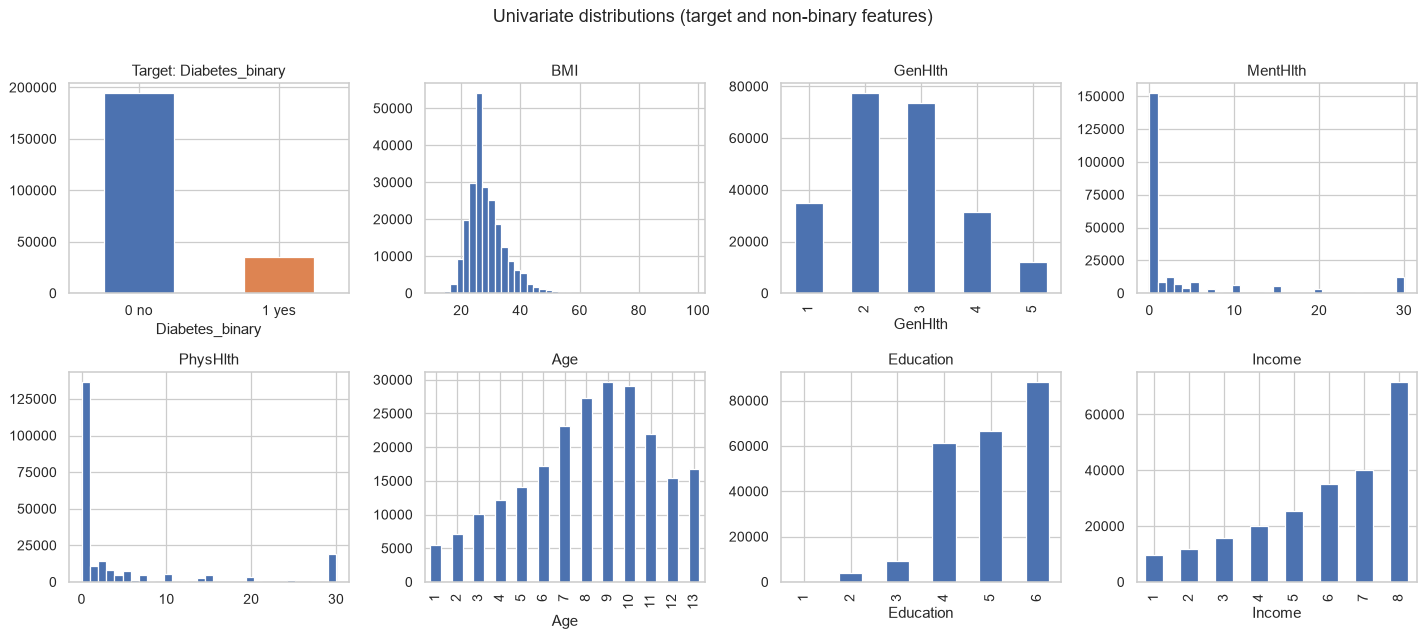

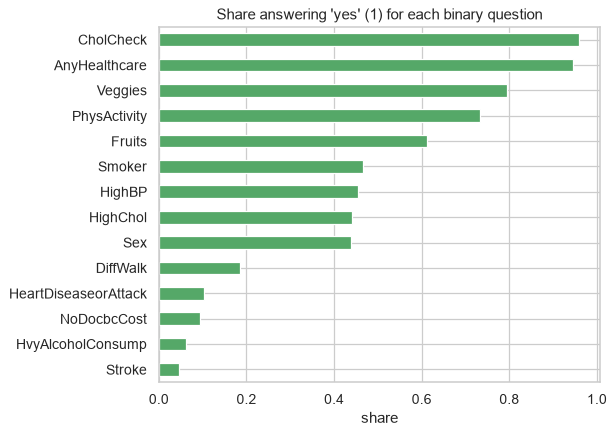

BMI percentiles (1%, 50%, 99%): [18.0, 27.0, 50.0] | max 98
Share with MentHlth == 0: 0.66, PhysHlth == 0: 0.60


In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.ravel()
df[TARGET].value_counts().sort_index().plot.bar(ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Target: Diabetes_binary"); axes[0].set_xticklabels(["0 no", "1 yes"], rotation=0)
for ax, c in zip(axes[1:], NUMERIC):
    if df[c].nunique() > 15:
        ax.hist(df[c], bins=40 if c == "BMI" else 31, color="#4C72B0")
    else:
        df[c].value_counts().sort_index().plot.bar(ax=ax, color="#4C72B0")
    ax.set_title(c)
plt.suptitle("Univariate distributions (target and non-binary features)", y=1.01)
plt.tight_layout(); plt.savefig(REPORTS / "eda_univariate.png", bbox_inches="tight"); plt.show()

prev = df[BINARY].mean().sort_values()
ax = prev.plot.barh(figsize=(7, 5), color="#55A868")
ax.set_title("Share answering 'yes' (1) for each binary question"); ax.set_xlabel("share")
plt.tight_layout(); plt.savefig(REPORTS / "eda_binary_prevalence.png", bbox_inches="tight"); plt.show()
print("BMI percentiles (1%, 50%, 99%):", df["BMI"].quantile([.01, .5, .99]).tolist(), "| max", df["BMI"].max())
print("Share with MentHlth == 0: %.2f, PhysHlth == 0: %.2f" % ((df.MentHlth == 0).mean(), (df.PhysHlth == 0).mean()))

`BMI` is right-skewed with a long tail of implausible-looking values; we keep them (they are self-reported height/weight derived and rare) and rely on scaling for the linear model and on trees being insensitive to outliers. `MentHlth` and `PhysHlth` are zero-inflated. Several binary questions are almost always "yes" (`CholCheck`, `AnyHealthcare`) or almost always "no" (`Stroke`, `HvyAlcoholConsump`), so they carry little information on their own.

### 3.2 Bivariate — diabetes rate by each feature

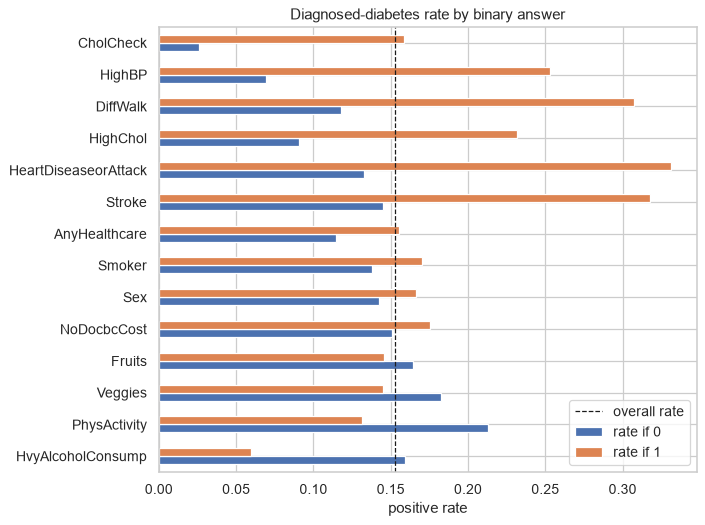

,rate if 0,rate if 1,lift (1 vs 0)
HvyAlcoholConsump,0.159,0.060,0.375
PhysActivity,0.213,0.131,0.616
Veggies,0.182,0.145,0.796
Fruits,0.164,0.146,0.888
NoDocbcCost,0.151,0.175,1.165
Sex,0.143,0.166,1.167
Smoker,0.138,0.170,1.239
AnyHealthcare,0.115,0.155,1.351
Stroke,0.145,0.318,2.188
HeartDiseaseorAttack,0.132,0.331,2.502


In [9]:
rate_bin = pd.DataFrame({c: df.groupby(c)[TARGET].mean() for c in BINARY}).T
rate_bin.columns = ["rate if 0", "rate if 1"]
rate_bin["lift (1 vs 0)"] = rate_bin["rate if 1"] / rate_bin["rate if 0"]
rate_bin = rate_bin.sort_values("lift (1 vs 0)")
ax = rate_bin[["rate if 0", "rate if 1"]].plot.barh(figsize=(8, 6))
ax.axvline(POS_RATE, ls="--", c="k", lw=1, label="overall rate"); ax.legend()
ax.set_title("Diagnosed-diabetes rate by binary answer"); ax.set_xlabel("positive rate")
plt.tight_layout(); plt.savefig(REPORTS / "eda_rate_binary.png", bbox_inches="tight"); plt.show()
rate_bin.round(3)

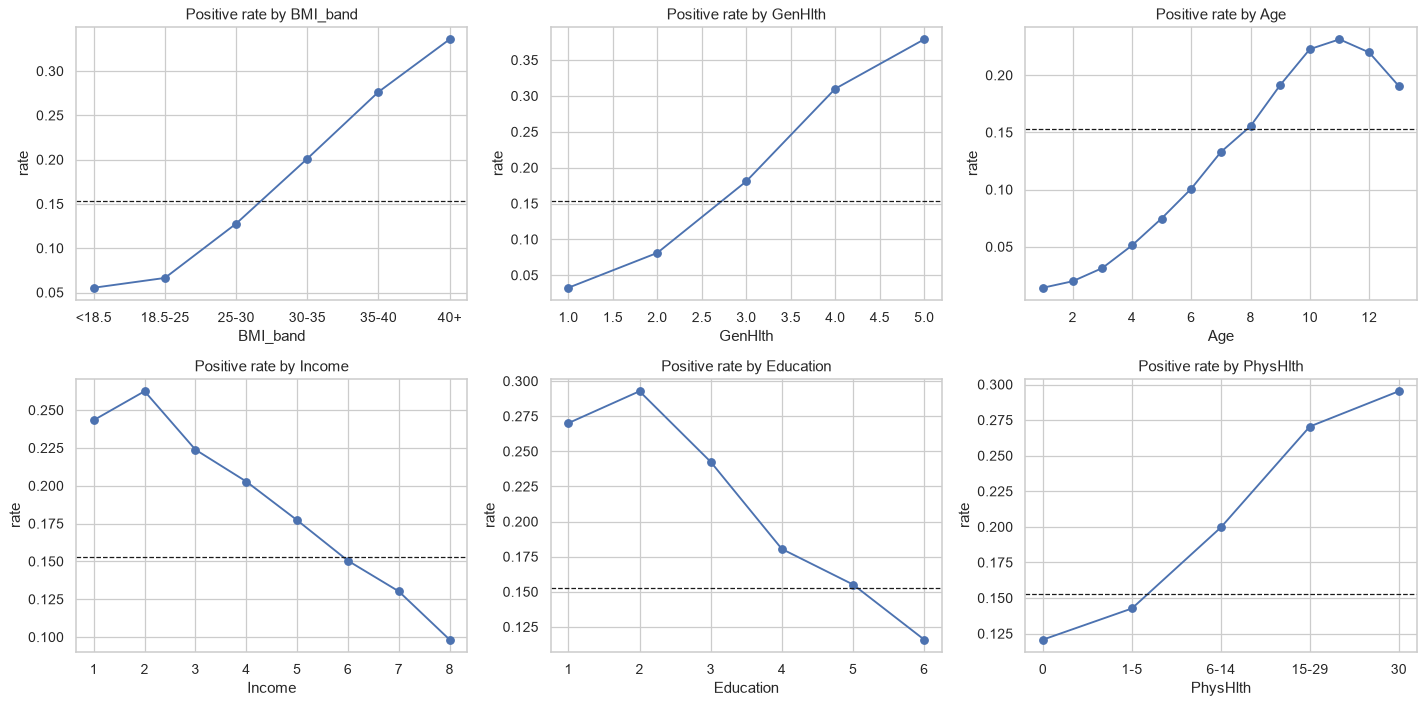

In [10]:
d = df.assign(BMI_band=pd.cut(df.BMI, [0, 18.5, 25, 30, 35, 40, 100],
                              labels=["<18.5", "18.5-25", "25-30", "30-35", "35-40", "40+"], right=False))
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), ["BMI_band", "GenHlth", "Age", "Income", "Education", "PhysHlth"]):
    g = d.groupby(c, observed=True)[TARGET].mean()
    if c == "PhysHlth":
        g = d.groupby(pd.cut(d.PhysHlth, [-1, 0, 5, 14, 29, 30], labels=["0", "1-5", "6-14", "15-29", "30"]), observed=True)[TARGET].mean()
    g.plot(ax=ax, marker="o"); ax.axhline(POS_RATE, ls="--", c="k", lw=1)
    ax.set_title(f"Positive rate by {c}"); ax.set_ylabel("rate")
plt.tight_layout(); plt.savefig(REPORTS / "eda_rate_ordinal.png", bbox_inches="tight"); plt.show()

### 3.3 Multivariate

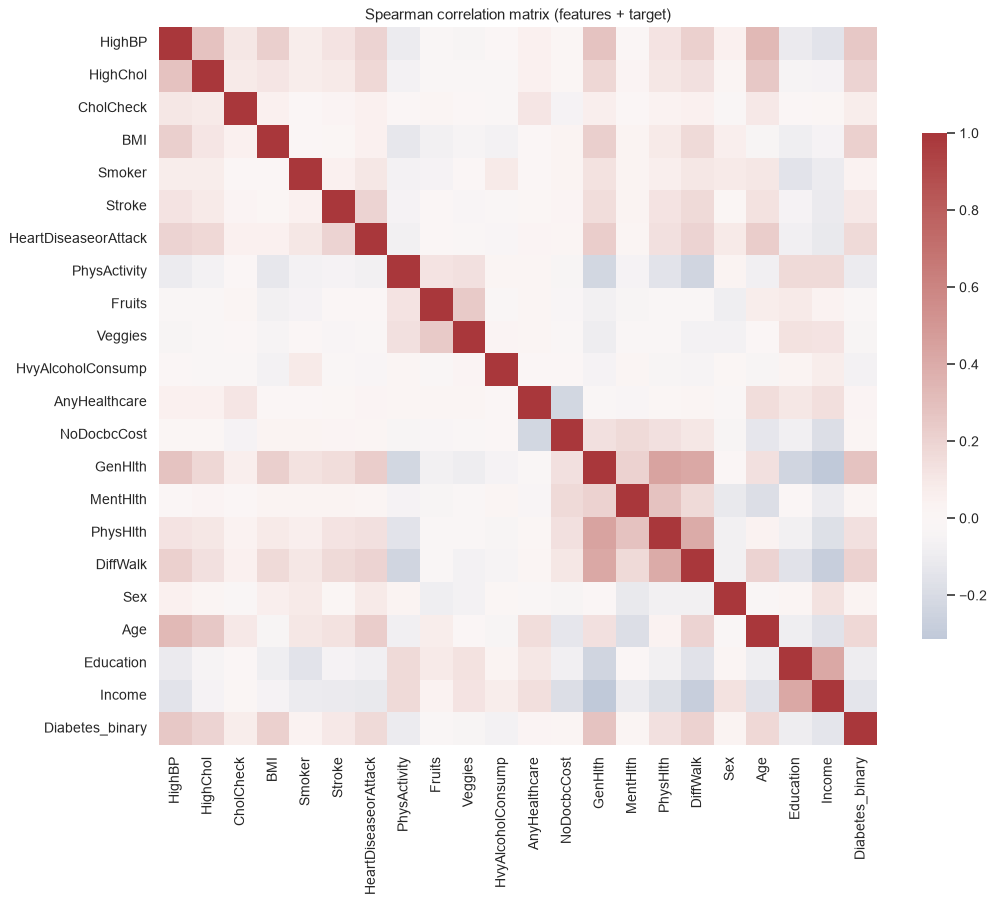

Correlation with target (Spearman), strongest first:
GenHlth                 0.273
HighBP                  0.254
BMI                     0.218
DiffWalk                0.205
HighChol                0.195
Age                     0.175
HeartDiseaseorAttack    0.168
Income                 -0.139
PhysHlth                0.137
PhysActivity           -0.100
Stroke                  0.099
Education              -0.097
CholCheck               0.073
HvyAlcoholConsump      -0.066
Smoker                  0.046
Veggies                -0.042
Sex                     0.033
AnyHealthcare           0.025
Fruits                 -0.025
NoDocbcCost             0.020
MentHlth                0.019


In [11]:
corr = df.corr(method="spearman")
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="vlag", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Spearman correlation matrix (features + target)")
plt.tight_layout(); plt.savefig(REPORTS / "eda_correlation.png", bbox_inches="tight"); plt.show()
print("Correlation with target (Spearman), strongest first:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_string())

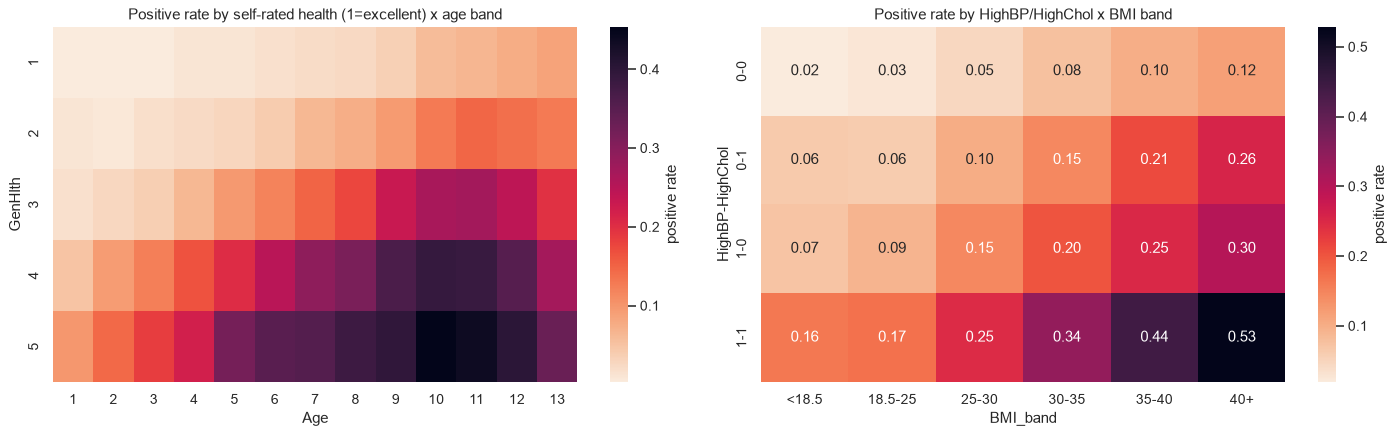

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
pv = d.pivot_table(index="GenHlth", columns="Age", values=TARGET, aggfunc="mean")
sns.heatmap(pv, cmap="rocket_r", ax=axes[0], cbar_kws={"label": "positive rate"})
axes[0].set_title("Positive rate by self-rated health (1=excellent) x age band")
pv2 = d.pivot_table(index=["HighBP", "HighChol"], columns="BMI_band", values=TARGET, aggfunc="mean", observed=True)
sns.heatmap(pv2, annot=True, fmt=".2f", cmap="rocket_r", ax=axes[1], cbar_kws={"label": "positive rate"})
axes[1].set_title("Positive rate by HighBP/HighChol x BMI band")
plt.tight_layout(); plt.savefig(REPORTS / "eda_multivariate.png", bbox_inches="tight"); plt.show()

In [13]:
# Numbers behind the written insights (computed, not typed).
r = lambda c, v: df.loc[df[c] == v, TARGET].mean()
print(f"GenHlth 1 (excellent): {r('GenHlth',1):.3f}  vs  GenHlth 5 (poor): {r('GenHlth',5):.3f}")
print(f"HighBP 0: {r('HighBP',0):.3f}  vs  HighBP 1: {r('HighBP',1):.3f}")
both = df[(df.HighBP == 1) & (df.HighChol == 1)][TARGET].mean(); none_ = df[(df.HighBP == 0) & (df.HighChol == 0)][TARGET].mean()
print(f"Neither HighBP nor HighChol: {none_:.3f}  vs  both: {both:.3f}")
print(f"BMI < 25: {df[df.BMI < 25][TARGET].mean():.3f}  vs  BMI >= 35: {df[df.BMI >= 35][TARGET].mean():.3f}")
print(f"Income 1 (<$10k): {r('Income',1):.3f}  vs  Income 8 (>=$75k): {r('Income',8):.3f}")
print(f"Age band 1 (18-24): {r('Age',1):.3f}  vs  Age band 10 (65-69): {r('Age',10):.3f}")

GenHlth 1 (excellent): 0.033  vs  GenHlth 5 (poor): 0.379
HighBP 0: 0.069  vs  HighBP 1: 0.253
Neither HighBP nor HighChol: 0.049  vs  both: 0.306
BMI < 25: 0.066  vs  BMI >= 35: 0.300
Income 1 (<$10k): 0.243  vs  Income 8 (>=$75k): 0.098
Age band 1 (18-24): 0.014  vs  Age band 10 (65-69): 0.223


### EDA insights

1. **Self-rated general health (`GenHlth`) has the steepest gradient**: the positive rate rises monotonically from "excellent" to "poor" — a single subjective question already separates risk strongly.
2. **Cardiometabolic history clusters with diabetes**: high blood pressure and high cholesterol each raise the rate substantially, and respondents with *both* are far above those with neither. The BMI × BP/cholesterol heatmap shows the effects stack.
3. **BMI shows a clear dose-response**: the rate climbs steadily across BMI bands, with the obese bands well above the overall rate.
4. **Age is a strong, roughly monotonic risk factor** up to the late 60s/70s bands, after which it flattens or dips slightly (survivor effect / smaller groups).
5. **Socio-economic gradient**: lower income and lower education go with higher rates. These attributes are useful predictors but are also *sensitive*, so we check model recall across them in the fairness section.

Lifestyle flags (`Fruits`, `Veggies`, `Smoker`) have much weaker univariate associations, and correlations among features are moderate (largest among `GenHlth`, `PhysHlth`, `DiffWalk`), so multicollinearity is not a blocking issue.

## 4. Preprocessing and train/test split

* **Split first.** A stratified 80/20 split (`random_state=42`) is made before any model, scaler or sampler is fitted. The test set is used only once, in Section 7.
* **All preprocessing lives inside an sklearn `Pipeline` / `ColumnTransformer`**, so it is re-fitted inside every CV fold (no leakage) and is saved together with the model for the app.
* Binary flags pass through unchanged. `BMI`, the day counts and the ordinal scales are **standardised** (needed by logistic regression; harmless for trees). Ordinal scales are kept as ordered integers instead of one-hot encoding because their effect on risk is close to monotonic (Section 3.2) and it keeps the model small and the explainer readable.
* No imputation is needed (no missing values), but the pipeline would fail loudly on unexpected NaNs rather than silently guessing.

In [14]:
import gc
del d, corr, pv, pv2; gc.collect()     # free EDA copies before modelling (low-RAM machine)
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print("train", X_train.shape, "positive rate %.4f" % y_train.mean())
print("test ", X_test.shape, "positive rate %.4f" % y_test.mean())

# Stratified ~50K sample of TRAIN for model comparison and hyper-parameter search (keeps runtime low).
X_s, _, y_s, _ = train_test_split(X_train, y_train, train_size=SAMPLE_N, stratify=y_train, random_state=RS)
print("tuning sample", X_s.shape, "positive rate %.4f" % y_s.mean())

def make_pre(features):
    num = [c for c in features if c not in BINARY]
    binf = [c for c in features if c in BINARY]
    return ColumnTransformer([("num", StandardScaler(), num), ("bin", "passthrough", binf)],
                             verbose_feature_names_out=False)

train (183579, 21) positive rate 0.1529
test  (45895, 21) positive rate 0.1529


tuning sample (50000, 21) positive rate 0.1529


## 5. Models and imbalance strategies

* **Baseline:** `DummyClassifier(strategy="prior")` — always predicts the majority class with the training prior as probability. Any useful model must beat it on recall, ROC-AUC and PR-AUC.
* **Candidates:** Logistic Regression (interpretable, linear), Random Forest (bagged trees), HistGradientBoosting (boosted trees, fast on large tabular data).
* **Imbalance strategies compared** for each candidate with 5-fold `StratifiedKFold` on the training sample:
  1. **none** — plain model, probability threshold 0.5;
  2. **class_weight="balanced"** — re-weights the minority class in the loss;
  3. **SMOTE** — synthetic minority over-sampling *inside* an `imblearn` pipeline, so only the training folds are resampled.

  A fourth strategy, **threshold tuning**, is applied later to the final model: its threshold is moved until recall reaches the target. Threshold-free metrics (ROC-AUC, PR-AUC) show whether a strategy improves the *ranking* itself or only shifts the default cut-off.

In [15]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
SCORING = {"recall": "recall", "precision": make_scorer(precision_score, zero_division=0), "f1": "f1", "roc_auc": "roc_auc",
           "pr_auc": "average_precision", "brier": "neg_brier_score"}

def base_models(cw=None):
    return {
        "LogisticRegression": LogisticRegression(max_iter=2000, class_weight=cw),
        "RandomForest": RandomForestClassifier(n_estimators=150, min_samples_leaf=10, n_jobs=-1,
                                               class_weight=cw, random_state=RS),
        "HistGradientBoosting": HistGradientBoostingClassifier(class_weight=cw, random_state=RS),
    }

rows = []
t = time.time()
res = cross_validate(Pipeline([("pre", make_pre(FEATURES)), ("model", DummyClassifier(strategy="prior"))]),
                     X_s, y_s, cv=cv5, scoring=SCORING)
rows.append({"model": "Dummy (prior)", "strategy": "none", **{k: res[f"test_{k}"].mean() for k in SCORING}})
for strategy in ["none", "class_weight", "SMOTE"]:
    for name, est in base_models("balanced" if strategy == "class_weight" else None).items():
        steps = [("pre", make_pre(FEATURES))] + ([("smote", SMOTE(random_state=RS))] if strategy == "SMOTE" else []) + [("model", est)]
        pipe = (ImbPipeline if strategy == "SMOTE" else Pipeline)(steps)
        res = cross_validate(pipe, X_s, y_s, cv=cv5, scoring=SCORING, n_jobs=1)
        rows.append({"model": name, "strategy": strategy, **{k: res[f"test_{k}"].mean() for k in SCORING}})
cv_table = pd.DataFrame(rows)
cv_table["brier"] = -cv_table["brier"]
print(f"CV comparison took {time.time()-t:.0f}s")
cv_table.round(4)

CV comparison took 34s


,model,strategy,recall,precision,f1,roc_auc,pr_auc,brier
0,Dummy (prior),none,0.0000,0.0000,0.0000,0.5000,0.1529,0.1295
1,LogisticRegression,none,0.1370,0.5200,0.2168,0.8020,0.3969,0.1093
2,RandomForest,none,0.0891,0.5827,0.1545,0.8045,0.4131,0.1079
3,HistGradientBoosting,none,0.1364,0.5629,0.2196,0.8072,0.4176,0.1075
4,LogisticRegression,class_weight,0.7518,0.3162,0.4452,0.8026,0.3952,0.1858
5,RandomForest,class_weight,0.7302,0.3250,0.4498,0.8054,0.4109,0.1724
6,HistGradientBoosting,class_weight,0.7714,0.3119,0.4442,0.8071,0.4168,0.1813
7,LogisticRegression,SMOTE,0.7474,0.3165,0.4447,0.7998,0.3913,0.1849
8,RandomForest,SMOTE,0.4217,0.4161,0.4188,0.7991,0.3941,0.1249
9,HistGradientBoosting,SMOTE,0.2231,0.5037,0.3091,0.8052,0.4122,0.1092


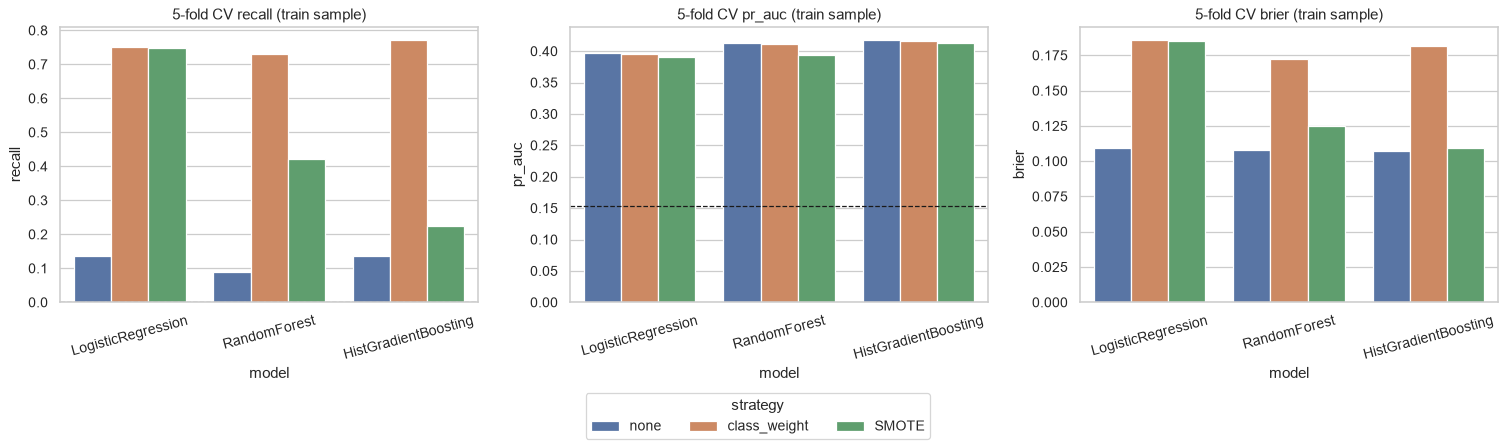

Mean over the three model families:
               recall  roc_auc  pr_auc   brier
strategy                                     
SMOTE         0.4641   0.8014  0.3992  0.1397
class_weight  0.7511   0.8050  0.4076  0.1798
none          0.1208   0.8046  0.4092  0.1082

Highest mean PR-AUC: 'none' | PR-AUC spread across strategies: 0.0100
Recall at 0.5 rises from 0.121 (none) to 0.751 (class_weight) and 0.464 (SMOTE), while Brier worsens from 0.1082 to 0.1798 / 0.1397.


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
plot_df = cv_table[cv_table.model != "Dummy (prior)"]
for ax, metric in zip(axes, ["recall", "pr_auc", "brier"]):
    sns.barplot(data=plot_df, x="model", y=metric, hue="strategy", ax=ax)
    ax.set_title(f"5-fold CV {metric} (train sample)"); ax.tick_params(axis="x", rotation=15)
    if metric != "brier":
        ax.axhline(cv_table.loc[0, metric], ls="--", c="k", lw=1)
    ax.get_legend().remove()
fig.legend(*axes[0].get_legend_handles_labels(), title="strategy", loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.savefig(REPORTS / "cv_imbalance_comparison.png", bbox_inches="tight"); plt.show()

agg = plot_df.groupby("strategy")[["recall", "roc_auc", "pr_auc", "brier"]].mean()
print("Mean over the three model families:\n", agg.round(4))
best_rank = agg["pr_auc"].idxmax()
print(f"\nHighest mean PR-AUC: '{best_rank}' | PR-AUC spread across strategies: {agg.pr_auc.max()-agg.pr_auc.min():.4f}")
print(f"Recall at 0.5 rises from {agg.loc['none','recall']:.3f} (none) to {agg.loc['class_weight','recall']:.3f} (class_weight) "
      f"and {agg.loc['SMOTE','recall']:.3f} (SMOTE), while Brier worsens from {agg.loc['none','brier']:.4f} to "
      f"{agg.loc['class_weight','brier']:.4f} / {agg.loc['SMOTE','brier']:.4f}.")

**Reading the comparison.** Without any imbalance handling, the default 0.5 cut-off gives a recall far below the screening target. Class weighting and SMOTE push recall up mainly by **shifting the cut-off**; the threshold-free PR-AUC / ROC-AUC barely change (or drop, for SMOTE), and both make the predicted probabilities systematically too high (worse Brier score). Since the app must show an honest probability, the final model handles imbalance with **threshold tuning on top of a calibrated, unweighted model**: we keep the best ranking and the best probabilities, then choose the cut-off that delivers the recall we need. The printed lines above give the exact figures.

## 6. Hyper-parameter tuning (train sample only)

Each model family is tuned with stratified 3-fold CV on the 50K training sample, optimising **PR-AUC** (average precision), the threshold-free metric most sensitive to how well the minority class is ranked. The best configuration is then refitted on the **full training set**.

In [17]:
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RS)
searches = {
    "LogisticRegression": GridSearchCV(
        Pipeline([("pre", make_pre(FEATURES)), ("model", LogisticRegression(max_iter=3000, solver="liblinear"))]),
        {"model__C": [0.001, 0.01, 0.1, 1, 10], "model__l1_ratio": [0.0, 1.0]},
        scoring="average_precision", cv=cv3, n_jobs=1),
    "RandomForest": RandomizedSearchCV(
        Pipeline([("pre", make_pre(FEATURES)), ("model", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RS))]),
        {"model__max_depth": [8, 12, 16, 20, None], "model__min_samples_leaf": [5, 10, 20, 50],
         "model__max_features": ["sqrt", 0.3, 0.5]},
        n_iter=8, scoring="average_precision", cv=cv3, random_state=RS, n_jobs=1),
    "HistGradientBoosting": RandomizedSearchCV(
        Pipeline([("pre", make_pre(FEATURES)), ("model", HistGradientBoostingClassifier(random_state=RS))]),
        {"model__learning_rate": [0.03, 0.05, 0.1, 0.2], "model__max_leaf_nodes": [15, 31, 63],
         "model__min_samples_leaf": [20, 50, 100, 200], "model__l2_regularization": [0.0, 0.1, 1.0],
         "model__max_iter": [200, 400]},
        n_iter=12, scoring="average_precision", cv=cv3, random_state=RS, n_jobs=1),
}
tune_rows = []
for name, s in searches.items():
    t = time.time(); s.fit(X_s, y_s)
    tune_rows.append({"model": name, "cv_pr_auc": s.best_score_, "seconds": round(time.time() - t),
                      "best_params": {k.replace("model__", ""): v for k, v in s.best_params_.items()}})
tune_table = pd.DataFrame(tune_rows).sort_values("cv_pr_auc", ascending=False)
BEST = tune_table.iloc[0]["model"]
print("Best family by tuned CV PR-AUC:", BEST)
tune_table

Best family by tuned CV PR-AUC: HistGradientBoosting


,model,cv_pr_auc,seconds,best_params
2,HistGradientBoosting,0.417073,21,"{'min_samples_leaf': 200, 'max_leaf_nodes': 15, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 1.0}"
1,RandomForest,0.412736,26,"{'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 12}"
0,LogisticRegression,0.396367,12,"{'C': 10, 'l1_ratio': 1.0}"


In [18]:
# Refit every tuned configuration on the FULL training set.
tuned = {}
for name, s in searches.items():
    t = time.time()
    tuned[name] = sklearn.base.clone(s.best_estimator_).fit(X_train, y_train)
    print(f"{name:22s} refit on {len(X_train):,} rows in {time.time()-t:.0f}s")

LogisticRegression     refit on 183,579 rows in 7s


RandomForest           refit on 183,579 rows in 7s


HistGradientBoosting   refit on 183,579 rows in 3s


## 7. Final model, calibration, threshold and test-set evaluation

1. **Calibration.** The best tuned pipeline is wrapped in `CalibratedClassifierCV` (isotonic, 3-fold) and fitted on the full training set, so that a predicted 0.30 means roughly a 30% chance of being positive.
2. **Screening threshold.** Chosen on **out-of-fold** training predictions (3-fold `cross_val_predict`) as the *highest* threshold that still reaches recall ≥ 0.80. The test set plays no part in choosing it.
3. **Test evaluation**, once: confusion matrix, precision / recall / F1, ROC-AUC, PR-AUC, Brier score and a reliability curve.

**No test-set leakage:** the screening threshold and the final model are chosen using training data only (cross-validated out-of-fold predictions); the test set is used once, for the final scores.

In [19]:
def pick_threshold(y_true, proba, target=TARGET_RECALL):
    prec, rec, thr = precision_recall_curve(y_true, proba)
    ok = np.where(rec[:-1] >= target)[0]          # rec[i] corresponds to thr[i]
    return float(thr[ok[-1]])

def metrics_at(y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    return {"recall": recall_score(y_true, pred), "precision": precision_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0), "roc_auc": roc_auc_score(y_true, proba),
            "pr_auc": average_precision_score(y_true, proba), "brier": brier_score_loss(y_true, proba)}

t = time.time()
final_model = CalibratedClassifierCV(sklearn.base.clone(searches[BEST].best_estimator_), method="isotonic", cv=3)
final_model.fit(X_train, y_train)
oof = cross_val_predict(CalibratedClassifierCV(sklearn.base.clone(searches[BEST].best_estimator_), method="isotonic", cv=3),
                        X_train, y_train, cv=cv3, method="predict_proba")[:, 1]
THR_FULL = pick_threshold(y_train, oof)
print(f"Calibrated {BEST} fitted + OOF threshold search in {time.time()-t:.0f}s")
print(f"Screening threshold (OOF recall >= {TARGET_RECALL}): {THR_FULL:.4f}")
print("OOF metrics at that threshold:", {k: round(v, 4) for k, v in metrics_at(y_train, oof, THR_FULL).items()})

Calibrated HistGradientBoosting fitted + OOF threshold search in 23s
Screening threshold (OOF recall >= 0.8): 0.1475
OOF metrics at that threshold: {'recall': 0.8001, 'precision': 0.307, 'f1': 0.4438, 'roc_auc': 0.8144, 'pr_auc': 0.431, 'brier': 0.1059}


In [20]:
p_full = final_model.predict_proba(X_test)[:, 1]
baseline = Pipeline([("pre", make_pre(FEATURES)), ("model", DummyClassifier(strategy="prior"))]).fit(X_train, y_train)
p_base = baseline.predict_proba(X_test)[:, 1]

test_rows = [{"stage": "test", "model": "Dummy (prior) @0.5", **metrics_at(y_test, p_base, 0.5)}]
for name, mdl in tuned.items():
    test_rows.append({"stage": "test", "model": f"{name} tuned, uncalibrated @0.5",
                      **metrics_at(y_test, mdl.predict_proba(X_test)[:, 1], 0.5)})
FULL_METRICS = metrics_at(y_test, p_full, THR_FULL)
test_rows.append({"stage": "test", "model": f"FINAL: {BEST} calibrated @screening thr", **FULL_METRICS})
test_table = pd.DataFrame(test_rows)
test_table.round(4)

,stage,model,recall,precision,f1,roc_auc,pr_auc,brier
0,test,Dummy (prior) @0.5,0.0000,0.0000,0.0000,0.5000,0.1529,0.1295
1,test,"LogisticRegression tuned, uncalibrated @0.5",0.1539,0.5395,0.2394,0.8102,0.4142,0.1074
2,test,"RandomForest tuned, uncalibrated @0.5",0.1054,0.6325,0.1807,0.8169,0.4438,0.1055
3,test,"HistGradientBoosting tuned, uncalibrated @0.5",0.1539,0.6061,0.2454,0.8184,0.4450,0.1049
4,test,FINAL: HistGradientBoosting calibrated @screening thr,0.7988,0.3137,0.4505,0.8187,0.4445,0.1049


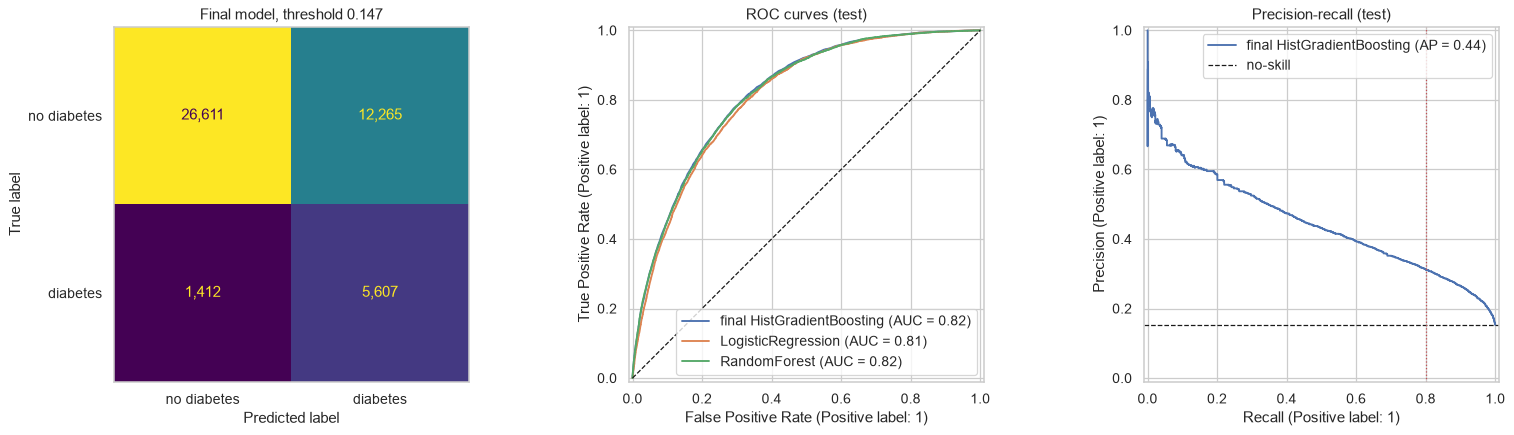

Of 7,019 positive test respondents, 5,607 are flagged (79.9%); 12,265 of 38,876 negatives are also flagged (31.5%).
Share of all test respondents sent for a blood test: 38.9%; about 3.2 referrals per true positive found.


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cm = confusion_matrix(y_test, (p_full >= THR_FULL).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["no diabetes", "diabetes"]).plot(ax=axes[0], colorbar=False, values_format=",")
axes[0].set_title(f"Final model, threshold {THR_FULL:.3f}"); axes[0].grid(False)
RocCurveDisplay.from_predictions(y_test, p_full, ax=axes[1], name=f"final {BEST}")
for name, mdl in tuned.items():
    if name != BEST:
        RocCurveDisplay.from_predictions(y_test, mdl.predict_proba(X_test)[:, 1], ax=axes[1], name=name)
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_title("ROC curves (test)")
PrecisionRecallDisplay.from_predictions(y_test, p_full, ax=axes[2], name=f"final {BEST}")
axes[2].axhline(y_test.mean(), ls="--", c="k", lw=1, label="no-skill"); axes[2].axvline(TARGET_RECALL, ls=":", c="r", lw=1)
axes[2].set_title("Precision-recall (test)"); axes[2].legend()
plt.tight_layout(); plt.savefig(REPORTS / "test_confusion_roc_pr.png", bbox_inches="tight"); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"Of {tp+fn:,} positive test respondents, {tp:,} are flagged ({tp/(tp+fn):.1%}); "
      f"{fp:,} of {tn+fp:,} negatives are also flagged ({fp/(tn+fp):.1%}).")
print(f"Share of all test respondents sent for a blood test: {(tp+fp)/cm.sum():.1%}; "
      f"about {(tp+fp)/max(tp,1):.1f} referrals per true positive found.")

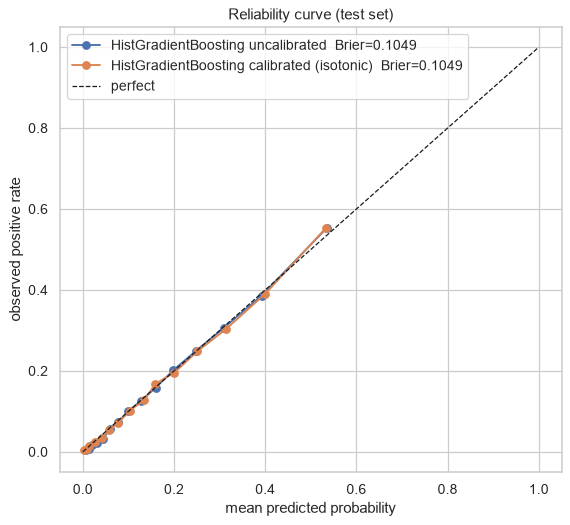

Mean predicted probability 0.1545 vs observed test positive rate 0.1529


In [22]:
p_unc = tuned[BEST].predict_proba(X_test)[:, 1]
fig, ax = plt.subplots(figsize=(6.5, 6))
for lab, pr in [(f"{BEST} uncalibrated", p_unc), (f"{BEST} calibrated (isotonic)", p_full)]:
    fx, fy = calibration_curve(y_test, pr, n_bins=15, strategy="quantile")
    ax.plot(fy, fx, marker="o", label=f"{lab}  Brier={brier_score_loss(y_test, pr):.4f}")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed positive rate"); ax.legend()
ax.set_title("Reliability curve (test set)")
plt.tight_layout(); plt.savefig(REPORTS / "calibration_curve.png", bbox_inches="tight"); plt.show()
print(f"Mean predicted probability {p_full.mean():.4f} vs observed test positive rate {y_test.mean():.4f}")

# Free the non-final refitted models (a deep RandomForest can take hundreds of MB).
import gc
for name in [n for n in tuned if n != BEST]:
    del tuned[name]
for name in [n for n in searches if n != BEST]:
    searches[name].best_estimator_ = None
gc.collect();

### 7.1 Error analysis

Which positives does the model miss (false negatives), and how do they differ from the positives it catches?

In [23]:
ev = X_test.assign(y=y_test.values, p=p_full, pred=(p_full >= THR_FULL).astype(int))
pos = ev[ev.y == 1]
cmp = pd.DataFrame({"missed (FN)": pos[pos.pred == 0][FEATURES].mean(),
                    "caught (TP)": pos[pos.pred == 1][FEATURES].mean()})
cmp["difference"] = cmp["missed (FN)"] - cmp["caught (TP)"]
print(f"False negatives: {(pos.pred == 0).sum():,} | true positives: {(pos.pred == 1).sum():,}")
cmp.reindex(cmp["difference"].abs().sort_values(ascending=False).index).round(3).head(10)

False negatives: 1,412 | true positives: 5,607


,missed (FN),caught (TP),difference
PhysHlth,3.361,9.305,-5.943
BMI,27.929,33.119,-5.190
MentHlth,2.813,5.051,-2.238
Age,8.370,9.627,-1.257
GenHlth,2.462,3.537,-1.074
Income,5.954,4.953,1.001
HighBP,0.363,0.852,-0.489
HighChol,0.390,0.747,-0.357
Education,5.012,4.657,0.355
DiffWalk,0.123,0.444,-0.321


In [24]:
fn_by = pos.groupby("GenHlth")["pred"].agg(lambda s: 1 - s.mean()).rename("miss rate among positives")
print(fn_by.round(3).to_string())
print("\nHighest-confidence false positives (top 5 predicted probabilities among true negatives):")
ev[(ev.y == 0)].nlargest(5, "p")[["p", "GenHlth", "HighBP", "HighChol", "BMI", "Age", "DiffWalk", "HeartDiseaseorAttack"]].round(3)

GenHlth
1    0.761
2    0.516
3    0.179
4    0.063
5    0.033

Highest-confidence false positives (top 5 predicted probabilities among true negatives):


,p,GenHlth,HighBP,HighChol,BMI,Age,DiffWalk,HeartDiseaseorAttack
31201,0.936,5,1,1,52,10,1,1
26201,0.785,5,1,1,44,9,1,1
221463,0.753,5,1,1,55,7,1,1
166331,0.753,5,1,1,52,10,1,1
172642,0.753,5,1,1,42,12,1,1


The missed positives look like the general population: better self-rated health, less often high blood pressure / cholesterol, lower BMI and younger age. In other words, the survey answers simply carry no warning sign for them — these are diagnosed diabetics whose answers look healthy, for example people whose diabetes is well managed. The most confident false positives are older respondents with poor health, high BP/cholesterol and heart disease: people for whom a blood test is clinically reasonable anyway. Errors therefore come from the information limits of a self-reported questionnaire rather than from a bug in the pipeline.

### 7.2 Fairness check — recall across sensitive groups

A screening tool that catches 80% of cases overall but far fewer in one group would widen existing health gaps. We compare recall (and the share flagged) at the single global threshold.

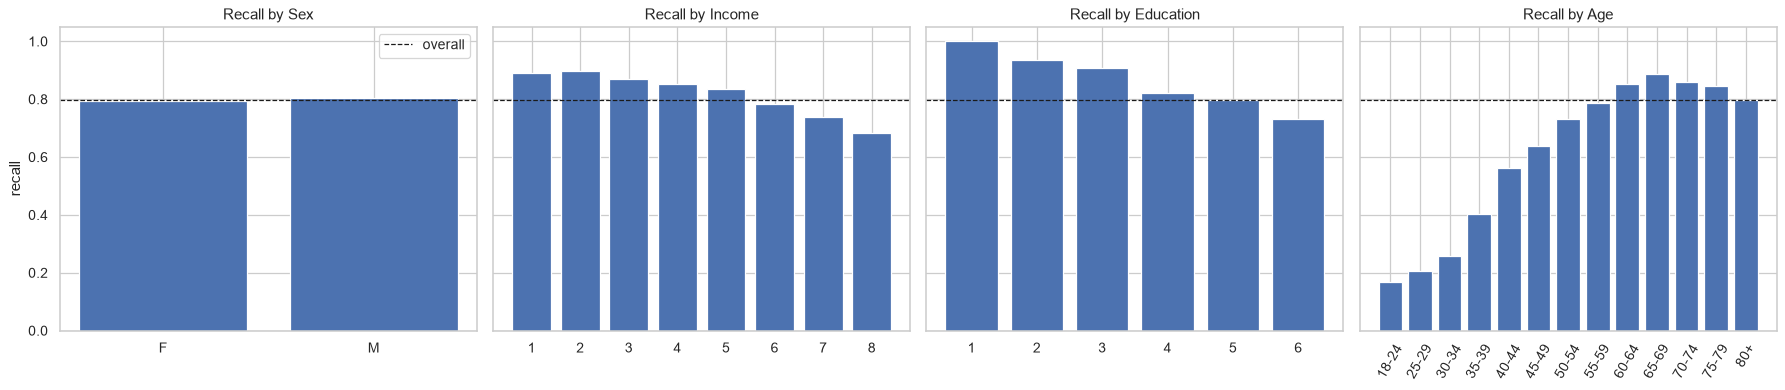

Sex       recall range (groups with >=50 positives): 0.795 - 0.803
Income    recall range (groups with >=50 positives): 0.683 - 0.899
Education recall range (groups with >=50 positives): 0.733 - 0.935
Age       recall range (groups with >=50 positives): 0.258 - 0.886


n  positives  prevalence  recall  precision  \
attribute group                                                    
Sex       0      25531       3627       0.142   0.795      0.318   
          1      20364       3392       0.167   0.803      0.310   
Income    1       1966        483       0.246   0.890      0.363   
          2       2392        622       0.260   0.899      0.363   
          3       3215        762       0.237   0.870      0.368   
          4       3955        811       0.205   0.852      0.334   
          5       5083        902       0.177   0.835      0.320   
          6       6994       1030       0.147   0.783      0.293   
          7       8120       1043       0.128   0.739      0.282   
          8      14170       1366       0.096   0.683      0.271   
Education 1         32          6       0.188   1.000      0.286   
          2        826        260       0.315   0.935      0.411   
          3       1876        484       0.258   0.909      0.381   
          4      12172       2174       0.179   0.821      0.314   
          5      13333       2053       0.154   0.797      0.312   
          6      17656       2042       0.116   0.733      0.290   
Age       1       1155         12       0.010   0.167      0.333   
          2       1403         29       0.021   0.207      0.273   
          3       2001         66       0.033   0.258      0.207   
          4       2453        129       0.053   0.403      0.291   
          5       2847        204       0.072   0.564      0.274   
          6       3400        332       0.098   0.639      0.298   
          7       4492        630       0.140   0.733      0.326   
          8       5401        854       0.158   0.786      0.315   
          9       5939       1149       0.193   0.852      0.340   
          10      5846       1305       0.223   0.886      0.336   
          11      4452        991       0.223   0.861      0.312   
          12      3085        667       0.216   0.844      0.296   
          13      3421        651       0.190   0.797      0.267   

                 flagged share  
attribute group                 
Sex       0              0.355  
          1              0.432  
Income    1              0.603  
          2              0.643  
          3              0.560  
          4              0.523  
          5              0.462  
          6              0.394  
          7              0.336  
          8              0.243  
Education 1              0.656  
          2              0.715  
          3              0.616  
          4              0.468  
          5              0.394  
          6              0.292  
Age       1              0.005  
          2              0.016  
          3              0.041  
          4              0.073  
          5              0.147  
          6              0.209  
          7              0.315  
          8              0.395  
          9              0.485  
          10             0.588  
          11             0.615  
          12             0.617  
          13             0.568

In [25]:
AGE_LABELS = {1: "18-24", 2: "25-29", 3: "30-34", 4: "35-39", 5: "40-44", 6: "45-49", 7: "50-54",
              8: "55-59", 9: "60-64", 10: "65-69", 11: "70-74", 12: "75-79", 13: "80+"}
def group_report(col):
    g = ev.groupby(col)
    out = pd.DataFrame({"n": g.size(), "positives": g.y.sum(), "prevalence": g.y.mean(),
                        "recall": g.apply(lambda s: recall_score(s.y, s.pred, zero_division=0)),
                        "precision": g.apply(lambda s: precision_score(s.y, s.pred, zero_division=0)),
                        "flagged share": g.pred.mean()})
    return out
fair = {c: group_report(c) for c in ["Sex", "Income", "Education", "Age"]}
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
for ax, (c, t_) in zip(axes, fair.items()):
    idx = [AGE_LABELS[i] for i in t_.index] if c == "Age" else (["F", "M"] if c == "Sex" else t_.index.astype(str))
    ax.bar(idx, t_["recall"], color="#4C72B0"); ax.axhline(FULL_METRICS["recall"], ls="--", c="k", lw=1, label="overall")
    ax.set_title(f"Recall by {c}"); ax.tick_params(axis="x", rotation=60 if c == "Age" else 0)
axes[0].set_ylabel("recall"); axes[0].legend()
plt.tight_layout(); plt.savefig(REPORTS / "fairness_recall.png", bbox_inches="tight"); plt.show()
for c, t_ in fair.items():
    t2 = t_[t_.positives >= 50]
    print(f"{c:9s} recall range (groups with >=50 positives): {t2.recall.min():.3f} - {t2.recall.max():.3f}")
pd.concat(fair, names=["attribute", "group"]).round(3)

Recall differs mostly along **age**: young respondents, whose prevalence is low, are flagged far less often, so a larger share of their (rare) cases is missed; older groups are caught at or above the target. Differences by sex are small. For income and education the lower groups — which have higher prevalence — get *higher* recall, so the tool does not under-serve the disadvantaged groups at this threshold, but it flags them more often (more referrals). The age gap is the main fairness caveat: a deployment aimed at younger adults would need a lower, age-specific threshold or a different tool. Exact ranges are printed above.

## 8. Stretch goal — the smallest useful question set

A 21-question form is long. We look for the shortest questionnaire that keeps most of the screening power.

* **Ranking.** Features are ranked by **permutation importance** (drop in PR-AUC when a column is shuffled) of a gradient-boosting model, measured on a validation split carved out of the training set (the test set stays untouched). An L1-regularised logistic regression ranking is shown alongside as a cross-check.
* **Curve.** For k = 1…21 top-ranked questions, a class-weighted gradient-boosting model is trained on the inner-train split and scored on validation (ROC-AUC, PR-AUC, recall at 0.5).
* **Elbow rule (coded):** the smallest k between 5 and 7 whose validation ROC-AUC is within 0.01 of the all-21 model; if none qualifies, k = 7. All 21 items are self-reported survey answers — none needs a lab test — so the only practical constraint is that `HighBP`/`HighChol` rely on the person having been told by a clinician, which we note as a limitation.

Ranking took 7s; Spearman agreement perm vs L1: 0.87


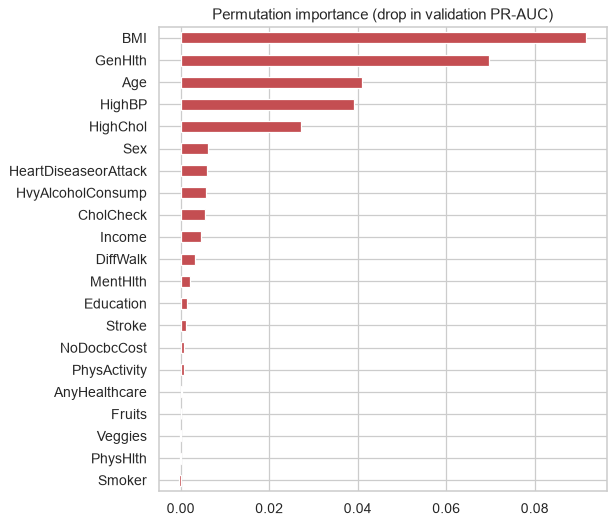

,perm_importance,perm_rank,l1_abs_coef,l1_rank
BMI,0.0916,1,0.4008,5
GenHlth,0.0696,2,0.5217,4
Age,0.0410,3,0.3855,6
HighBP,0.0391,4,0.7093,1
HighChol,0.0272,5,0.5420,3
Sex,0.0062,6,0.2052,8
HeartDiseaseorAttack,0.0059,7,0.1721,9
HvyAlcoholConsump,0.0057,8,0.5832,2
CholCheck,0.0056,9,0.3378,7
Income,0.0046,10,0.0893,10


In [26]:
X_in, X_val, y_in, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=RS)
t = time.time()
hgb_rank = HistGradientBoostingClassifier(random_state=RS).fit(X_in, y_in)
X_val_s, _, y_val_s, _ = train_test_split(X_val, y_val, train_size=20_000, stratify=y_val, random_state=RS)
pi = permutation_importance(hgb_rank, X_val_s, y_val_s, scoring="average_precision", n_repeats=5, random_state=RS, n_jobs=1)
perm = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)

l1 = Pipeline([("pre", make_pre(FEATURES)),
               ("model", LogisticRegression(solver="liblinear", l1_ratio=1.0, C=0.01, max_iter=3000))]).fit(X_in, y_in)
l1_coef = pd.Series(np.abs(l1.named_steps["model"].coef_[0]), index=l1.named_steps["pre"].get_feature_names_out())
rank_table = pd.DataFrame({"perm_importance": perm, "perm_rank": np.arange(1, 22)})
rank_table["l1_abs_coef"] = l1_coef.reindex(rank_table.index)
rank_table["l1_rank"] = rank_table["l1_abs_coef"].rank(ascending=False, method="min").astype(int)
print(f"Ranking took {time.time()-t:.0f}s; Spearman agreement perm vs L1: "
      f"{rank_table[['perm_rank','l1_rank']].corr(method='spearman').iloc[0,1]:.2f}")
ax = perm.iloc[::-1].plot.barh(figsize=(7, 6), color="#C44E52")
ax.set_title("Permutation importance (drop in validation PR-AUC)")
plt.tight_layout(); plt.savefig(REPORTS / "permutation_importance.png", bbox_inches="tight"); plt.show()
rank_table.round(4)

Curve took 19s | all-21 val ROC-AUC 0.8179 | chosen k = 6
Short question set: ['HighBP', 'HighChol', 'BMI', 'GenHlth', 'Sex', 'Age']


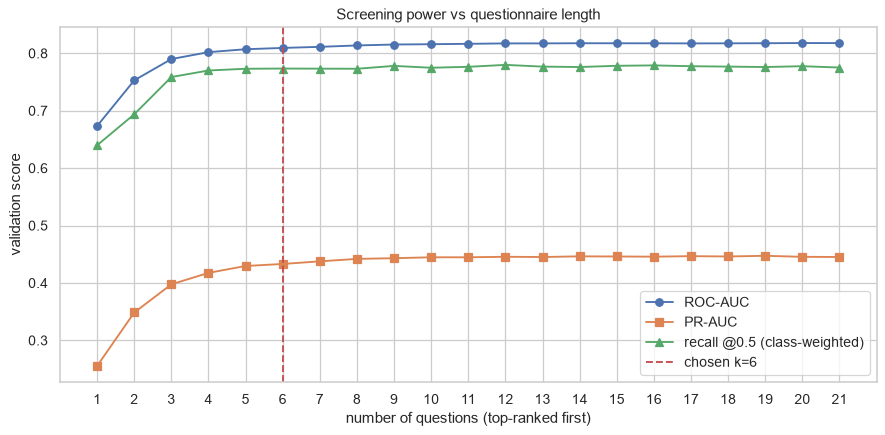

,k,added,roc_auc,pr_auc,recall@0.5
0,1,BMI,0.6735,0.2556,0.6400
1,2,GenHlth,0.7530,0.3486,0.6939
2,3,Age,0.7901,0.3977,0.7587
3,4,HighBP,0.8021,0.4176,0.7701
4,5,HighChol,0.8072,0.4296,0.7731
5,6,Sex,0.8094,0.4331,0.7735
6,7,HeartDiseaseorAttack,0.8113,0.4377,0.7733
7,8,HvyAlcoholConsump,0.8138,0.4420,0.7731
8,9,CholCheck,0.8154,0.4432,0.7781
9,10,Income,0.8159,0.4448,0.7749


In [27]:
ORDER = list(perm.index)
curve = []
t = time.time()
for k in range(1, 22):
    cols = ORDER[:k]
    mdl = HistGradientBoostingClassifier(class_weight="balanced", random_state=RS).fit(X_in[cols], y_in)
    pv = mdl.predict_proba(X_val[cols])[:, 1]
    curve.append({"k": k, "added": cols[-1], "roc_auc": roc_auc_score(y_val, pv),
                  "pr_auc": average_precision_score(y_val, pv), "recall@0.5": recall_score(y_val, pv >= 0.5)})
curve = pd.DataFrame(curve)
auc_all = curve.loc[curve.k == 21, "roc_auc"].item()
ok = curve[(curve.k.between(5, 7)) & (curve.roc_auc >= auc_all - 0.01)]
K_SHORT = int(ok.k.min()) if len(ok) else 7
SHORT = [c for c in FEATURES if c in ORDER[:K_SHORT]]     # keep dataset order for the app
print(f"Curve took {time.time()-t:.0f}s | all-21 val ROC-AUC {auc_all:.4f} | chosen k = {K_SHORT}")
print("Short question set:", SHORT)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(curve.k, curve.roc_auc, marker="o", label="ROC-AUC")
ax.plot(curve.k, curve.pr_auc, marker="s", label="PR-AUC")
ax.plot(curve.k, curve["recall@0.5"], marker="^", label="recall @0.5 (class-weighted)")
ax.axvline(K_SHORT, ls="--", c="r", label=f"chosen k={K_SHORT}")
ax.set_xticks(range(1, 22)); ax.set_xlabel("number of questions (top-ranked first)"); ax.set_ylabel("validation score")
ax.set_title("Screening power vs questionnaire length"); ax.legend()
plt.tight_layout(); plt.savefig(REPORTS / "questions_curve.png", bbox_inches="tight"); plt.show()
curve.round(4)

**Short model.** The same model family and tuned hyper-parameters as the full model are refitted on the chosen questions only, calibrated the same way, and given its own out-of-fold screening threshold (recall ≥ 0.80 on training data).

In [28]:
t = time.time()
def short_pipe():
    p = sklearn.base.clone(searches[BEST].best_estimator_)
    p.steps[0] = ("pre", make_pre(SHORT))
    return p
short_model = CalibratedClassifierCV(short_pipe(), method="isotonic", cv=3).fit(X_train[SHORT], y_train)
oof_s = cross_val_predict(CalibratedClassifierCV(short_pipe(), method="isotonic", cv=3),
                          X_train[SHORT], y_train, cv=cv3, method="predict_proba")[:, 1]
THR_SHORT = pick_threshold(y_train, oof_s)
p_short = short_model.predict_proba(X_test[SHORT])[:, 1]
SHORT_METRICS = metrics_at(y_test, p_short, THR_SHORT)
print(f"Short model fitted in {time.time()-t:.0f}s | threshold {THR_SHORT:.4f}")
print("Test metrics:", {k: round(v, 4) for k, v in SHORT_METRICS.items()})
print("Full model:  ", {k: round(v, 4) for k, v in FULL_METRICS.items()})
print(f"ROC-AUC kept: {SHORT_METRICS['roc_auc']/FULL_METRICS['roc_auc']:.1%} of the full model with {len(SHORT)} of 21 questions")

Short model fitted in 17s | threshold 0.1429
Test metrics: {'recall': 0.8115, 'precision': 0.3019, 'f1': 0.4401, 'roc_auc': 0.8122, 'pr_auc': 0.4327, 'brier': 0.106}
Full model:   {'recall': 0.7988, 'precision': 0.3137, 'f1': 0.4505, 'roc_auc': 0.8187, 'pr_auc': 0.4445, 'brier': 0.1049}
ROC-AUC kept: 99.2% of the full model with 6 of 21 questions


### 8.1 Explainers for the app and the saved artifacts

The app shows *why* a score is high. For that we fit a plain `StandardScaler + LogisticRegression` on the full training set (one for all 21 questions, one for the short set) and export its means, scales, coefficients and intercept; the per-question contribution is `coef × (x − mean) / scale` in log-odds. This explainer is a transparent approximation used only for the explanation — the displayed probability comes from the calibrated model.

Risk bands: **low** below the lower of the two screening thresholds, **high** from 0.5 upward (calibrated probability of at least one in two), **moderate** in between.

In [29]:
def explainer(features):
    sc = StandardScaler().fit(X_train[features])
    lr = LogisticRegression(max_iter=3000).fit(sc.transform(X_train[features]), y_train)
    return {"features": list(features), "coef": lr.coef_[0].tolist(), "mean": sc.mean_.tolist(),
            "scale": sc.scale_.tolist(), "intercept": float(lr.intercept_[0])}

BASE_METRICS = metrics_at(y_test, p_base, 0.5)
# whole-percent cut points so the app's percent display never contradicts the band legend;
# floor keeps low_max at or below both screening thresholds (which stay unrounded)
risk_bands = {"low_max": float(np.floor(min(THR_FULL, THR_SHORT) * 100) / 100), "high_min": 0.50}
assert risk_bands["low_max"] < risk_bands["high_min"]
meta = {
    "features_full": FEATURES, "features_short": SHORT,
    "threshold_full": THR_FULL, "threshold_short": THR_SHORT, "target_recall": TARGET_RECALL,
    "risk_bands": risk_bands,
    "explainer": explainer(FEATURES), "explainer_short": explainer(SHORT),
    "metrics": {"full": FULL_METRICS, "short": SHORT_METRICS, "baseline": BASE_METRICS},
    "positive_rate": float(POS_RATE), "n_rows": int(N_ROWS), "n_rows_raw": int(n_raw),
    "data_year": DATA_YEAR, "data_year_note": "UCI page says BRFSS 2014; a rebuild from raw BRFSS 2015 matches data/diabetes.csv row for row",
    "model_family": BEST, "sklearn_version": sklearn.__version__,
}
joblib.dump(final_model, MODELS / "full_model.joblib", compress=3)
joblib.dump(short_model, MODELS / "short_model.joblib", compress=3)
(MODELS / "meta.json").write_text(json.dumps(meta, indent=2))
for f in ["full_model.joblib", "short_model.joblib", "meta.json"]:
    print(f"{f:20s} {(MODELS / f).stat().st_size/1e6:.2f} MB")

full_model.joblib    0.42 MB
short_model.joblib   0.41 MB
meta.json            0.00 MB


## 9. Population segmentation (K-Means + PCA)

The classifier answers *"is this person at risk?"*. A public-health team also needs to know *"what kinds of people are at risk, and what should we offer each group?"*. We answer that with unsupervised clustering on the **training split** (the test set is not used).

**Feature choice.** We cluster on ten interpretable, mostly *modifiable* risk factors: `BMI`, `Age`, `GenHlth`, `HighBP`, `HighChol`, `PhysActivity`, `DiffWalk`, `PhysHlth`, `Smoker`, `HvyAlcoholConsump`. We deliberately leave out:
* the target, so that segments are defined by risk factors and their diabetes rate can be compared afterwards;
* `Sex`, `Income`, `Education`, so that people are not grouped by sensitive socio-economic attributes and every segment maps onto an action a programme can take;
* low-information flags (`CholCheck`, `AnyHealthcare`, `Stroke`, ...) and `MentHlth`, `Fruits`, `Veggies`, which add noise more than structure.

`Age` stays in because it is the strongest non-modifiable risk factor and decides which programmes apply.

**Method.** `StandardScaler` → `KMeans` inside one `Pipeline`, so the saved model scales new answers exactly as in training. k is chosen from 2–8 with the **elbow** (inertia) and the **silhouette** score (on a 5,000-row sample, because silhouette is quadratic in n). The rule in code is: the k in 4–6 with the highest silhouette, since 4–6 segments is a number an outreach team can act on. Ward **agglomerative clustering** on the same sample is a cross-check: if both methods find similar groups (adjusted Rand index), the segments are not an artefact of K-Means.

k search took 4s | chosen k = 4


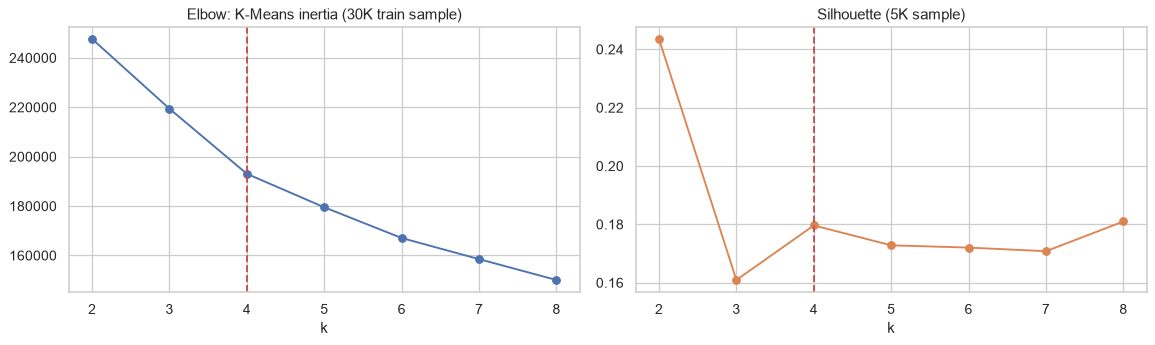

,k,inertia,silhouette
0,2,247664.8749,0.2436
1,3,219409.5043,0.1609
2,4,193062.3445,0.1797
3,5,179509.1424,0.1728
4,6,167069.1251,0.1720
5,7,158523.3525,0.1708
6,8,150068.9188,0.1810


In [30]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

SEG_FEATURES = ["BMI", "Age", "GenHlth", "HighBP", "HighChol", "PhysActivity", "DiffWalk",
                "PhysHlth", "Smoker", "HvyAlcoholConsump"]
X_seg = X_train[SEG_FEATURES]
X_seg_fit = train_test_split(X_seg, train_size=30_000, stratify=y_train, random_state=RS)[0]
X_sil = X_seg_fit.sample(5_000, random_state=RS)

def seg_pipe(k):
    return Pipeline([("scale", StandardScaler()), ("kmeans", KMeans(n_clusters=k, n_init=10, random_state=RS))])

t = time.time()
k_rows = []
for k in range(2, 9):
    p = seg_pipe(k).fit(X_seg_fit)
    k_rows.append({"k": k, "inertia": p["kmeans"].inertia_,
                   "silhouette": silhouette_score(p["scale"].transform(X_sil), p.predict(X_sil))})
k_table = pd.DataFrame(k_rows)
K_SEG = int(k_table[k_table.k.between(4, 6)].sort_values("silhouette", ascending=False).iloc[0]["k"])
print(f"k search took {time.time()-t:.0f}s | chosen k = {K_SEG}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(k_table.k, k_table.inertia, marker="o"); axes[0].set_title("Elbow: K-Means inertia (30K train sample)")
axes[1].plot(k_table.k, k_table.silhouette, marker="o", c="#DD8452"); axes[1].set_title("Silhouette (5K sample)")
for ax in axes:
    ax.axvline(K_SEG, ls="--", c="r"); ax.set_xlabel("k")
plt.tight_layout(); plt.savefig(REPORTS / "segments_elbow_silhouette.png", bbox_inches="tight"); plt.show()
k_table.round(4)

In [31]:
segments_model = seg_pipe(K_SEG).fit(X_seg)          # final fit on the full training split
seg_train = segments_model.predict(X_seg)

# Cross-check with Ward agglomerative clustering on the 5K sample.
Z_sil = segments_model["scale"].transform(X_sil)
km_sil = segments_model.predict(X_sil)
agg_sil = AgglomerativeClustering(n_clusters=K_SEG, linkage="ward").fit_predict(Z_sil)
print(f"Silhouette on 5K sample: K-Means {silhouette_score(Z_sil, km_sil):.3f} | Agglomerative (Ward) {silhouette_score(Z_sil, agg_sil):.3f}")
print(f"Agreement between the two partitions (adjusted Rand index): {adjusted_rand_score(km_sil, agg_sil):.3f}")
print("Cross-tab K-Means (rows) vs Agglomerative (columns):")
pd.crosstab(km_sil, agg_sil)

Silhouette on 5K sample: K-Means 0.180 | Agglomerative (Ward) 0.148
Agreement between the two partitions (adjusted Rand index): 0.619
Cross-tab K-Means (rows) vs Agglomerative (columns):


col_0,0,1,2,3
row_0,,,,
0,431,114,0,1678
1,1333,118,0,32
2,9,1003,1,0
3,0,0,281,0


Overall training positive rate: 0.153
[2] High risk: walking difficulty, many poor physical-health days          size  18.9% | diabetes rate 0.324 (2.1x)
     action: Priority outreach: offer an HbA1c or fasting-glucose test now and link positives to clinical care — plus physical-activity promotion, low-impact or home-based exercise options.
[1] Moderate risk: high blood pressure, no mobility limits                 size  30.1% | diabetes rate 0.212 (1.4x)
     action: Offer a blood-sugar test at the next routine visit and refer to a diet-and-activity prevention programme.
[3] Low risk: heavy drinkers, smokers                                      size   6.0% | diabetes rate 0.057 (0.4x)
     action: General prevention messaging and routine re-screening every few years — plus a brief alcohol intervention.
[0] Low risk: normal blood pressure, good general health                   size  45.0% | diabetes rate 0.054 (0.4x)
     action: General prevention messaging and routine re-screening ev

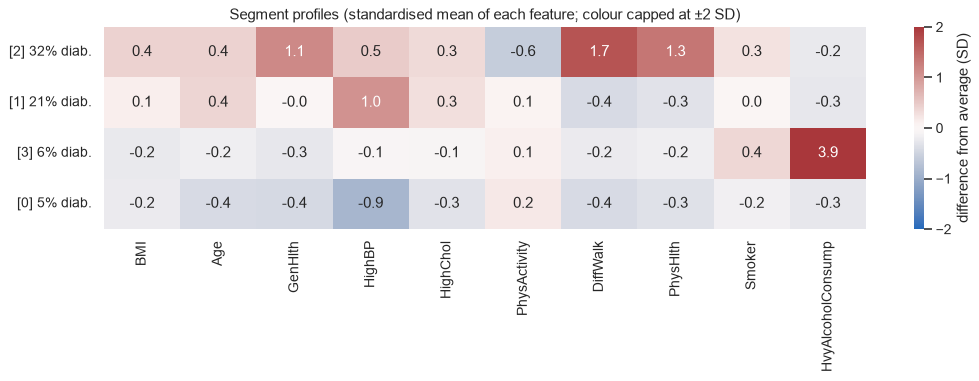

,BMI,Age,GenHlth,HighBP,HighChol,PhysActivity,DiffWalk,PhysHlth,Smoker,HvyAlcoholConsump,size_share,diabetes_rate,name
segment,,,,,,,,,,,,,
0,27.120,6.825,2.142,0.011,0.282,0.818,0.022,1.703,0.385,0.000,0.450,0.054,"Low risk: normal blood pressure, good general health"
1,29.589,9.261,2.571,0.976,0.582,0.764,0.028,1.775,0.466,0.000,0.301,0.212,"Moderate risk: high blood pressure, no mobility limits"
2,31.432,9.371,3.819,0.689,0.611,0.472,0.851,16.882,0.597,0.004,0.189,0.324,"High risk: walking difficulty, many poor physical-health days"
3,27.069,7.544,2.333,0.418,0.399,0.783,0.100,3.014,0.648,1.000,0.060,0.057,"Low risk: heavy drinkers, smokers"


In [32]:
prof = X_seg.assign(segment=seg_train).groupby("segment")[SEG_FEATURES].mean()
prof["size_share"] = pd.Series(seg_train).value_counts(normalize=True).sort_index()
prof["diabetes_rate"] = pd.Series(y_train.values).groupby(seg_train).mean()
z = (prof[SEG_FEATURES] - X_seg.mean()) / X_seg.std()      # how each segment differs from the average respondent

PHRASE = {("BMI", 1): "high BMI", ("BMI", -1): "lower BMI", ("Age", 1): "older", ("Age", -1): "younger",
          ("GenHlth", 1): "poor general health", ("GenHlth", -1): "good general health",
          ("HighBP", 1): "high blood pressure", ("HighBP", -1): "normal blood pressure",
          ("HighChol", 1): "high cholesterol", ("HighChol", -1): "normal cholesterol",
          ("PhysActivity", 1): "active", ("PhysActivity", -1): "inactive",
          ("DiffWalk", 1): "walking difficulty", ("DiffWalk", -1): "no mobility limits",
          ("PhysHlth", 1): "many poor physical-health days", ("PhysHlth", -1): "few poor physical-health days",
          ("Smoker", 1): "smokers", ("Smoker", -1): "non-smokers",
          ("HvyAlcoholConsump", 1): "heavy drinkers", ("HvyAlcoholConsump", -1): "non-heavy drinkers"}
BASE_ACTION = {"High risk": "Priority outreach: offer an HbA1c or fasting-glucose test now and link positives to clinical care",
               "Moderate risk": "Offer a blood-sugar test at the next routine visit and refer to a diet-and-activity prevention programme",
               "Low risk": "General prevention messaging and routine re-screening every few years"}
EXTRA = [("BMI", 1, "weight-management support"), ("PhysActivity", -1, "physical-activity promotion"),
         ("DiffWalk", 1, "low-impact or home-based exercise options"), ("Smoker", 1, "smoking-cessation support"),
         ("HvyAlcoholConsump", 1, "a brief alcohol intervention")]

def describe(sid, used):
    rel = prof.loc[sid, "diabetes_rate"] / POS_RATE
    tier = "High risk" if rel >= 1.5 else ("Low risk" if rel <= 0.6 else "Moderate risk")
    order = z.loc[sid].abs().sort_values(ascending=False).index
    words = [PHRASE[(f, int(np.sign(z.loc[sid, f])))] for f in order]
    name = f"{tier}: {words[0]}, {words[1]}"
    if name in used:
        name += f", {words[2]}"
    extras = [txt for f, sgn, txt in EXTRA if np.sign(z.loc[sid, f]) == sgn and abs(z.loc[sid, f]) >= 0.5]
    action = BASE_ACTION[tier] + (" — plus " + ", ".join(extras) if extras else "") + "."
    return name, action

names, actions, used = {}, {}, set()
for sid in prof.sort_values("diabetes_rate", ascending=False).index:
    names[sid], actions[sid] = describe(sid, used); used.add(names[sid])
prof["name"], prof["action"] = pd.Series(names), pd.Series(actions)
print(f"Overall training positive rate: {POS_RATE:.3f}")
for sid, r_ in prof.sort_values("diabetes_rate", ascending=False).iterrows():
    print(f"[{sid}] {r_['name']:70s} size {r_.size_share:6.1%} | diabetes rate {r_.diabetes_rate:.3f} ({r_.diabetes_rate/POS_RATE:.1f}x)")
    print(f"     action: {r_.action}")

fig, ax = plt.subplots(figsize=(12, 0.6 * K_SEG + 2))
sns.heatmap(z.loc[prof.sort_values("diabetes_rate", ascending=False).index].set_axis(
                [f"[{i}] {prof.loc[i,'diabetes_rate']:.0%} diab." for i in prof.sort_values("diabetes_rate", ascending=False).index]),
            cmap="vlag", center=0, vmin=-2, vmax=2, annot=True, fmt=".1f", ax=ax, cbar_kws={"label": "difference from average (SD)"})
ax.set_title("Segment profiles (standardised mean of each feature; colour capped at ±2 SD)")
plt.tight_layout(); plt.savefig(REPORTS / "segments_profile.png", bbox_inches="tight"); plt.show()
prof.drop(columns="action").round(3)

PCA explained variance: PC1 0.255, PC2 0.129 (together 0.384)
Loadings (top 3 per component):
  PC1: GenHlth +0.47, DiffWalk +0.45, PhysHlth +0.42
  PC2: Age +0.55, HighChol +0.47, HighBP +0.41


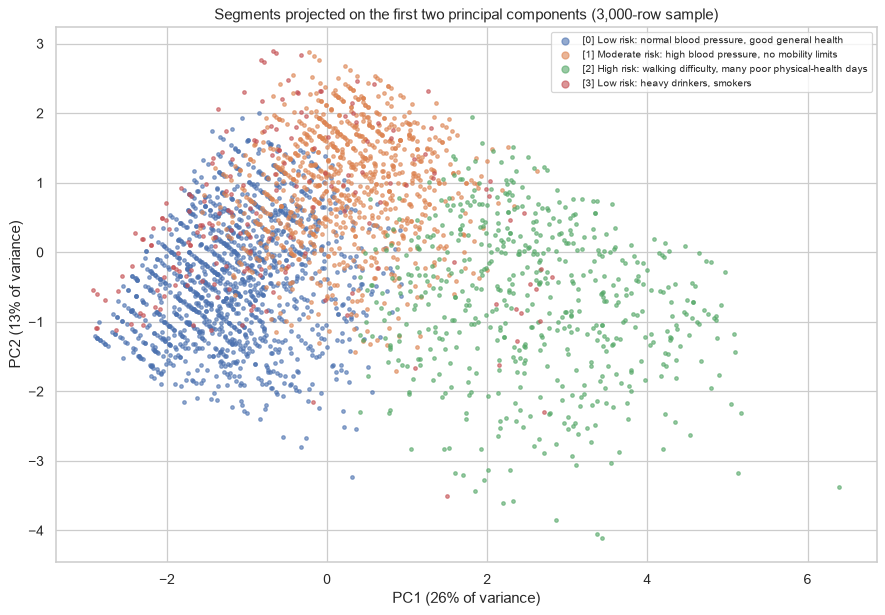

In [33]:
Z_train = segments_model["scale"].transform(X_seg)
pca = PCA(n_components=2, random_state=RS).fit(Z_train)
EV = pca.explained_variance_ratio_
print(f"PCA explained variance: PC1 {EV[0]:.3f}, PC2 {EV[1]:.3f} (together {EV.sum():.3f})")
print("Loadings (top 3 per component):")
load = pd.DataFrame(pca.components_.T, index=SEG_FEATURES, columns=["PC1", "PC2"])
for pc in ["PC1", "PC2"]:
    print(f"  {pc}:", ", ".join(f"{f} {load.loc[f, pc]:+.2f}" for f in load[pc].abs().sort_values(ascending=False).index[:3]))

pts_idx = train_test_split(np.arange(len(X_seg)), train_size=3000, stratify=seg_train, random_state=RS)[0]
xy = pca.transform(Z_train[pts_idx])
fig, ax = plt.subplots(figsize=(10, 7))
for sid in sorted(prof.index):
    m_ = seg_train[pts_idx] == sid
    ax.scatter(xy[m_, 0], xy[m_, 1], s=8, alpha=.6, label=f"[{sid}] {prof.loc[sid, 'name']}")
ax.set_xlabel(f"PC1 ({EV[0]:.0%} of variance)"); ax.set_ylabel(f"PC2 ({EV[1]:.0%} of variance)")
ax.set_title("Segments projected on the first two principal components (3,000-row sample)")
ax.legend(fontsize=8, loc="best", markerscale=2)
plt.tight_layout(); plt.savefig(REPORTS / "segments_pca.png", bbox_inches="tight"); plt.show()

In [34]:
segments_json = {
    "features": SEG_FEATURES, "k": K_SEG,
    "segments": [{"id": int(sid), "name": prof.loc[sid, "name"], "action": prof.loc[sid, "action"],
                  "size_share": float(prof.loc[sid, "size_share"]), "diabetes_rate": float(prof.loc[sid, "diabetes_rate"]),
                  "profile": {f: float(prof.loc[sid, f]) for f in SEG_FEATURES}} for sid in sorted(prof.index)],
    "pca": {"explained_variance": EV.tolist(),
            "points": [{"x": round(float(a), 3), "y": round(float(b), 3), "segment": int(s), "label": prof.loc[s, "name"],
                        "diabetes": int(d)}
                       for (a, b), s, d in zip(xy, seg_train[pts_idx], y_train.values[pts_idx])],
            # extras so the app can place a new respondent on the same plot: ((x - scaler_mean)/scaler_scale - pca_mean) @ components.T
            "components": pca.components_.tolist(), "pca_mean": pca.mean_.tolist(),
            "scaler_mean": segments_model["scale"].mean_.tolist(), "scaler_scale": segments_model["scale"].scale_.tolist()},
}
joblib.dump(segments_model, MODELS / "segments.joblib", compress=3)
(MODELS / "segments.json").write_text(json.dumps(segments_json, indent=1))
for f in ["segments.joblib", "segments.json"]:
    print(f"{f:16s} {(MODELS / f).stat().st_size/1e6:.2f} MB")

segments.joblib  0.09 MB
segments.json    0.48 MB


**Reading the segments.** The printed profiles give each segment's size, its diabetes rate compared with the average, the risk factors that set it apart, and a suggested action. Names and actions are produced by a fixed rule from the profile (risk tier from the diabetes rate, then the two most distinctive features). They do not depend on cluster numbering, so re-running the notebook gives the same names. The diabetes rate was **not** used to form the clusters. That several segments differ strongly in it shows that combinations of risk factors identify groups an outreach programme can target. Silhouette scores are modest, as is usual for data that is mostly binary: the segments are a useful summary of a continuum, not sharply separated populations. The agreement with Ward clustering, printed above, shows how stable they are.

## 10. Screening cost curve

The screening threshold is a budget decision. For every threshold from 0.02 to 0.80 we record recall, precision, the share of people flagged, and true positives / false positives / false negatives per 1,000 people screened. These come from the calibrated **test-set** probabilities of the final full and short models. The test set is only *described* here: the screening threshold itself was fixed earlier from training data. The curves are saved to `models/threshold_curve.json` for the app.

In [35]:
def curve_points(y_true, proba):
    y_arr, n, pts = np.asarray(y_true) == 1, len(y_true), []
    for t_ in np.round(np.arange(0.02, 0.8001, 0.01), 2):
        flag = proba >= t_
        tp_, fp_, fn_ = int((flag & y_arr).sum()), int((flag & ~y_arr).sum()), int((~flag & y_arr).sum())
        pts.append({"threshold": float(t_), "recall": round(tp_ / (tp_ + fn_), 4),
                    "precision": round(tp_ / (tp_ + fp_), 4) if tp_ + fp_ else 0.0, "flag_rate": round(float(flag.mean()), 4),
                    "tp_per_1000": round(1000 * tp_ / n, 2), "fp_per_1000": round(1000 * fp_ / n, 2), "fn_per_1000": round(1000 * fn_ / n, 2)})
    return pts

threshold_curve = {"full": {"model": "full", "points": curve_points(y_test, p_full)},
                   "short": {"model": "short", "points": curve_points(y_test, p_short)}}
(MODELS / "threshold_curve.json").write_text(json.dumps(threshold_curve, indent=1))
curve_full = pd.DataFrame(threshold_curve["full"]["points"]); curve_short = pd.DataFrame(threshold_curve["short"]["points"])
print(f"{len(curve_full)} thresholds per model written to models/threshold_curve.json")
curve_full[curve_full.threshold.isin([0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50])]

79 thresholds per model written to models/threshold_curve.json


,threshold,recall,precision,flag_rate,tp_per_1000,fp_per_1000,fn_per_1000
3,0.05,0.9590,0.2237,0.6556,146.66,508.94,6.28
8,0.10,0.8873,0.2713,0.5003,135.70,364.55,17.23
13,0.15,0.7963,0.3149,0.3868,121.78,265.00,31.16
18,0.20,0.7000,0.3518,0.3043,107.05,197.28,45.89
28,0.30,0.5100,0.4271,0.1827,78.00,104.65,74.93
38,0.40,0.3315,0.5069,0.1000,50.70,49.33,102.23
48,0.50,0.1422,0.6067,0.0358,21.75,14.10,131.19


**Cost example.** `COST_PER_TEST` below is an **assumed** price of one blood-sugar test plus the staff time to arrange it. It is *not* taken from the data; change it to the local figure. With it we compute the testing cost per 1,000 people screened and the **cost per true case found**, and compare with testing everyone.

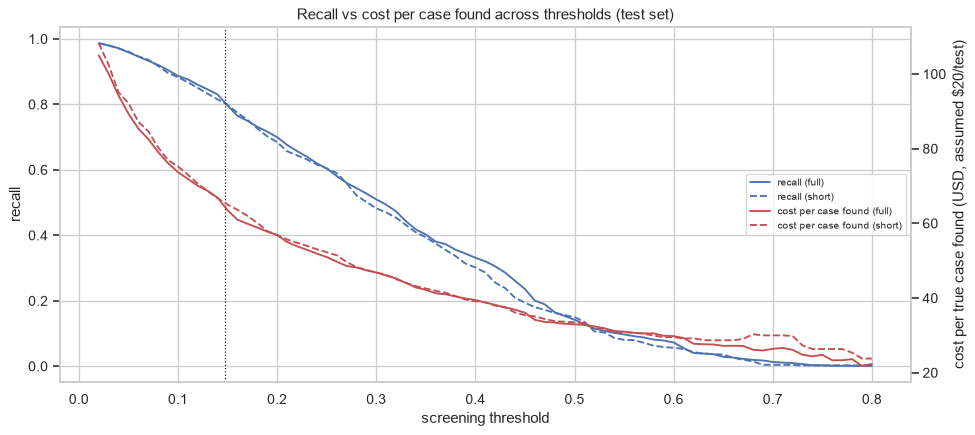

Assumed cost per test: $20
At the screening threshold 0.147 (full model): $7,788 per 1,000 screened, 122 cases found -> $64 per case found (recall 79.9%).
Testing everyone: $20,000 per 1,000 -> $131 per case found (recall 100%).
Saving vs testing everyone: 61% of the testing budget, for 20% of cases missed.


,threshold,recall,precision,flag_rate,cost_per_1000,cost_per_case_found
3,0.05,0.96,0.22,0.66,13112.0,89.40
8,0.10,0.89,0.27,0.50,10005.0,73.73
13,0.15,0.80,0.31,0.39,7735.6,63.52
18,0.20,0.70,0.35,0.30,6086.6,56.86
28,0.30,0.51,0.43,0.18,3653.0,46.83
48,0.50,0.14,0.61,0.04,717.0,32.97


In [36]:
COST_PER_TEST = 20.0      # ASSUMPTION (USD per HbA1c/fasting-glucose test incl. handling) — not from the dataset; edit freely

for c_ in (curve_full, curve_short):
    c_["cost_per_1000"] = (c_.tp_per_1000 + c_.fp_per_1000) * COST_PER_TEST
    c_["cost_per_case_found"] = c_.cost_per_1000 / c_.tp_per_1000.replace(0, np.nan)

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(curve_full.threshold, curve_full.recall, label="recall (full)", c="#4C72B0")
ax1.plot(curve_short.threshold, curve_short.recall, label="recall (short)", c="#4C72B0", ls="--")
ax1.set_xlabel("screening threshold"); ax1.set_ylabel("recall")
ax2 = ax1.twinx()
ax2.plot(curve_full.threshold, curve_full.cost_per_case_found, label="cost per case found (full)", c="#C44E52")
ax2.plot(curve_short.threshold, curve_short.cost_per_case_found, label="cost per case found (short)", c="#C44E52", ls="--")
ax2.set_ylabel(f"cost per true case found (USD, assumed ${COST_PER_TEST:.0f}/test)"); ax2.grid(False)
ax1.axvline(THR_FULL, c="k", ls=":", lw=1)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="center right", fontsize=8)
ax1.set_title("Recall vs cost per case found across thresholds (test set)")
plt.tight_layout(); plt.savefig(REPORTS / "threshold_cost_curve.png", bbox_inches="tight"); plt.show()

n_t = cm.sum()
cost_thr = 1000 * (tp + fp) / n_t * COST_PER_TEST
everyone = 1000 * COST_PER_TEST
print(f"Assumed cost per test: ${COST_PER_TEST:.0f}")
print(f"At the screening threshold {THR_FULL:.3f} (full model): ${cost_thr:,.0f} per 1,000 screened, "
      f"{1000*tp/n_t:.0f} cases found -> ${cost_thr/(1000*tp/n_t):,.0f} per case found (recall {tp/(tp+fn):.1%}).")
print(f"Testing everyone: ${everyone:,.0f} per 1,000 -> ${everyone/(1000*y_test.mean()):,.0f} per case found (recall 100%).")
print(f"Saving vs testing everyone: {1 - cost_thr/everyone:.0%} of the testing budget, for {fn/(tp+fn):.0%} of cases missed.")
curve_full.loc[curve_full.threshold.isin([0.05, 0.10, 0.15, 0.20, 0.30, 0.50]),
               ["threshold", "recall", "precision", "flag_rate", "cost_per_1000", "cost_per_case_found"]].round(2)

## 11. Results, business insight and limitations

### Final results table

CV rows are 5-fold means on the 50K training sample; test rows are computed once on the held-out 20% test set.

In [37]:
cv_out = cv_table.assign(stage="cv (train sample)", model=cv_table.model + " [" + cv_table.strategy + "] @0.5").drop(columns="strategy")
tuned_out = tune_table[["model", "cv_pr_auc"]].rename(columns={"cv_pr_auc": "pr_auc"}).assign(stage="tuned cv (train sample)")
final_rows = test_table.to_dict("records") + [
    {"stage": "test", "model": f"SHORT ({len(SHORT)} questions): {BEST} calibrated @screening thr", **SHORT_METRICS}]
results = pd.concat([cv_out, tuned_out, pd.DataFrame(final_rows)], ignore_index=True)
results = results[["stage", "model", "recall", "precision", "f1", "roc_auc", "pr_auc", "brier"]]
results.to_csv(REPORTS / "results.csv", index=False)
headline = pd.DataFrame({"baseline (Dummy)": BASE_METRICS, f"full ({BEST}, 21 q)": FULL_METRICS,
                         f"short ({len(SHORT)} q)": SHORT_METRICS}).T
print("Headline test metrics (screening thresholds: full %.3f, short %.3f)" % (THR_FULL, THR_SHORT))
display(headline.round(4))
results.round(4)

Headline test metrics (screening thresholds: full 0.147, short 0.143)


,recall,precision,f1,roc_auc,pr_auc,brier
baseline (Dummy),0.0000,0.0000,0.0000,0.5000,0.1529,0.1295
"full (HistGradientBoosting, 21 q)",0.7988,0.3137,0.4505,0.8187,0.4445,0.1049
short (6 q),0.8115,0.3019,0.4401,0.8122,0.4327,0.1060


,stage,model,recall,precision,f1,roc_auc,pr_auc,brier
0,cv (train sample),Dummy (prior) [none] @0.5,0.0000,0.0000,0.0000,0.5000,0.1529,0.1295
1,cv (train sample),LogisticRegression [none] @0.5,0.1370,0.5200,0.2168,0.8020,0.3969,0.1093
2,cv (train sample),RandomForest [none] @0.5,0.0891,0.5827,0.1545,0.8045,0.4131,0.1079
3,cv (train sample),HistGradientBoosting [none] @0.5,0.1364,0.5629,0.2196,0.8072,0.4176,0.1075
4,cv (train sample),LogisticRegression [class_weight] @0.5,0.7518,0.3162,0.4452,0.8026,0.3952,0.1858
5,cv (train sample),RandomForest [class_weight] @0.5,0.7302,0.3250,0.4498,0.8054,0.4109,0.1724
6,cv (train sample),HistGradientBoosting [class_weight] @0.5,0.7714,0.3119,0.4442,0.8071,0.4168,0.1813
7,cv (train sample),LogisticRegression [SMOTE] @0.5,0.7474,0.3165,0.4447,0.7998,0.3913,0.1849
8,cv (train sample),RandomForest [SMOTE] @0.5,0.4217,0.4161,0.4188,0.7991,0.3941,0.1249
9,cv (train sample),HistGradientBoosting [SMOTE] @0.5,0.2231,0.5037,0.3091,0.8052,0.4122,0.1092


In [38]:
cm_s = confusion_matrix(y_test, (p_short >= THR_SHORT).astype(int)); tn_s, fp_s, fn_s, tp_s = cm_s.ravel()
per1000 = lambda tp_, fp_: (1000 * (tp_ + fp_) / cm.sum(), 1000 * tp_ / cm.sum())
r_full, r_short = per1000(tp, fp), per1000(tp_s, fp_s)
print(f"Per 1,000 people screened with the full form: ~{r_full[0]:.0f} referred for a blood test, "
      f"~{r_full[1]:.0f} of them truly diagnosed diabetic (out of ~{1000*y_test.mean():.0f}).")
print(f"Per 1,000 people screened with the {len(SHORT)}-question form: ~{r_short[0]:.0f} referred, ~{r_short[1]:.0f} true cases found.")
print(f"Random referral of the same number of people would find only ~{r_full[0]*y_test.mean():.0f} cases.")
print(f"Total notebook runtime so far: {(time.time()-T0)/60:.1f} min")

Per 1,000 people screened with the full form: ~389 referred for a blood test, ~122 of them truly diagnosed diabetic (out of ~153).
Per 1,000 people screened with the 6-question form: ~411 referred, ~124 true cases found.
Random referral of the same number of people would find only ~60 cases.
Total notebook runtime so far: 3.3 min


### Business insight

* **The tool turns a free questionnaire into a targeted referral list.** At the screening threshold it catches about four in five respondents with diagnosed diabetes while referring only part of the population, and it finds far more cases per referral than random selection (see the per-1,000 figures above).
* **A few questions do most of the work.** The short form keeps nearly all of the ranking power of the 21-question model, so a 1-minute kiosk or web form is realistic. General health, blood pressure, BMI, age and cholesterol dominate the ranking.
* **Probabilities are calibrated**, so the app can show an honest "x in 100 people like you" figure instead of an unexplained score, and outreach teams can move the threshold to match their testing budget.
* **Operational lever:** the threshold is a business choice. Raising it lowers the number of blood tests but misses more cases. The cost curve (Section 10) turns this into money per case found under a stated cost assumption.
* **Segments turn scores into programmes.** The K-Means segments (Section 9) group respondents by risk-factor combinations that differ strongly in diabetes rate. Outreach can then match an action to a group (for example weight management, activity promotion or immediate testing) instead of sending one generic message.

### Limitations

* **Self-reported survey data.** Answers (including BMI from self-reported height/weight and "ever told high BP/cholesterol") can be wrong or unknown, and the label is self-reported diagnosis — undiagnosed diabetics appear as negatives, so true recall on undiagnosed people is unknown.
* **Not a diagnosis.** The output is a prompt to get a blood test, never a medical result; the app must say so.
* **Prediabetes is not captured.** The label is diagnosed diabetes only; prediabetes is coded 0. The tool flags people similar to diagnosed diabetics. Undiagnosed or prediabetic people likely look similar, but that is untested.
* **Sensitive attributes** (sex, income, education, age) are used as predictors. Recall is lower for younger adults (Section 7.2); deployment should monitor group-level recall and consider whether income/education should be asked at all.
* **Population and time shift.** US adults, one BRFSS year (2015; the UCI page says 2014, but a rebuild from raw 2015 data matches row for row), telephone survey; performance elsewhere or today is untested.
* **Duplicates removed** — a deliberate, slightly conservative choice; scores with duplicates kept would be a little higher.
* **Segments are descriptive.** They come from mostly binary survey answers, have modest silhouette scores and summarise a continuum. Segment names and actions are rule-generated suggestions, not clinical guidance.
* **Cost figures rest on an assumed test price** and ignore the downstream costs of missed cases and the value of early treatment.

### Self-check — reload the saved artifacts

In [39]:
meta_chk = json.loads((MODELS / "meta.json").read_text())
full_chk, short_chk = joblib.load(MODELS / "full_model.joblib"), joblib.load(MODELS / "short_model.joblib")
rows3 = X_test.iloc[:3].astype(int)   # plain int64, as the app will send
pf = full_chk.predict_proba(rows3[meta_chk["features_full"]])[:, 1]
ps = short_chk.predict_proba(rows3[meta_chk["features_short"]])[:, 1]
assert meta_chk["features_full"] == FEATURES and len(meta_chk["features_full"]) == 21
assert 5 <= len(meta_chk["features_short"]) <= 7 and set(meta_chk["features_short"]) <= set(FEATURES)
assert pf.shape == ps.shape == (3,) and ((0 <= pf) & (pf <= 1)).all() and ((0 <= ps) & (ps <= 1)).all()
assert np.allclose(pf, p_full[:3]) and np.allclose(ps, p_short[:3])
assert 0 < meta_chk["threshold_full"] < 1 and 0 < meta_chk["threshold_short"] < 1
assert meta_chk["risk_bands"]["low_max"] <= min(meta_chk["threshold_full"], meta_chk["threshold_short"]) < meta_chk["risk_bands"]["high_min"]
assert all(abs(v * 100 - round(v * 100)) < 1e-9 for v in meta_chk["risk_bands"].values())   # whole percents
for key in ["explainer", "explainer_short"]:
    e = meta_chk[key]
    assert len(e["features"]) == len(e["coef"]) == len(e["mean"]) == len(e["scale"])
for k in ["full", "short", "baseline"]:
    assert set(meta_chk["metrics"][k]) == {"recall", "precision", "f1", "roc_auc", "pr_auc", "brier"}
assert meta_chk["metrics"]["full"]["recall"] > 0.7 and meta_chk["metrics"]["full"]["roc_auc"] > meta_chk["metrics"]["baseline"]["roc_auc"]
seg_chk, seg_meta = joblib.load(MODELS / "segments.joblib"), json.loads((MODELS / "segments.json").read_text())
seg_ids = seg_chk.predict(rows3[seg_meta["features"]])
assert seg_meta["k"] == len(seg_meta["segments"]) and set(seg_ids) <= {s["id"] for s in seg_meta["segments"]}
assert abs(sum(s["size_share"] for s in seg_meta["segments"]) - 1) < 1e-6
assert len(seg_meta["pca"]["explained_variance"]) == 2 and len(seg_meta["pca"]["points"]) <= 3000
assert {"x", "y", "segment", "label"} <= set(seg_meta["pca"]["points"][0])
tc = json.loads((MODELS / "threshold_curve.json").read_text())
assert set(tc) == {"full", "short"} and all(len(tc[m]["points"]) == 79 for m in tc)
assert set(tc["full"]["points"][0]) == {"threshold", "recall", "precision", "flag_rate", "tp_per_1000", "fp_per_1000", "fn_per_1000"}
assert all(a["recall"] >= b["recall"] for a, b in zip(tc["full"]["points"], tc["full"]["points"][1:]))   # recall falls as threshold rises
print("segments for 3 test rows:", seg_ids)
print("full  model probabilities for 3 test rows:", pf.round(4))
print("short model probabilities for 3 test rows:", ps.round(4))
print(f"All artifact checks passed. Total runtime {(time.time()-T0)/60:.1f} min.")

segments for 3 test rows: [0 0 1]
full  model probabilities for 3 test rows: [0.2324 0.0077 0.0702]
short model probabilities for 3 test rows: [0.1835 0.0117 0.0802]
All artifact checks passed. Total runtime 3.3 min.
